# GPSA Analysis - 1YVL (no NTD) WT vs T385M vs R274W_T385M

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO


## Delta Energy Terms

### Load data

In [2]:
def load_finalenergy (mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = (f'../../data/1YVL_noNTD/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY.csv')
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the index of the line containing "Delta Energy Terms"
        start_idx = None
        for i, line in enumerate(lines):
            if "Delta Energy Terms" in line:
                start_idx = i + 1  # Start from the next line
                break

        if start_idx is None:
            raise ValueError("Section 'Delta Energy Terms' not found in the file")

        # Extract the lines after "Delta Energy Terms"
        data_lines = lines[start_idx:]
        data_string = ''.join(data_lines)
        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)
    return dfs


In [3]:
WT_delta_dfs = load_finalenergy('WT')
T385M_delta_dfs = load_finalenergy('T385M')
R274W_T385M_delta_dfs = load_finalenergy('R274W_T385M')

In [4]:
WT_delta_dfs[0].head()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
0,1000,0.0,0.0,0.0,-159.75,-83.97,0.0,0.0,86.80,-23.92,-243.72,62.88,-180.84
1,1001,0.0,0.0,0.0,-161.99,-81.83,0.0,0.0,86.08,-25.09,-243.82,60.99,-182.82
2,1002,0.0,0.0,0.0,-169.51,-79.54,-0.0,0.0,84.05,-25.52,-249.05,58.53,-190.52
3,1003,0.0,0.0,0.0,-158.45,-83.57,-0.0,-0.0,87.25,-24.34,-242.03,62.92,-179.11
4,1004,0.0,0.0,-0.0,-157.95,-87.64,0.0,-0.0,90.19,-24.58,-245.59,65.61,-179.99


Columns: 
- BOND: Bond stretching energy
- ANGLE: Angle bending energy
- DIHED: Dihedral (torsional) energy
- VDWAALS: van der Waals energy
- EEL: Electrostatic energy
- 1-4 VDW: 1-4 van der Waals energy
- 1-4 EEL: 1-4 Electrostatic energy
- EGB: Generalized Born energy
- ESURF: Surface (non-polar solvation) energy
- GGAS: Gas-phase energy. (BOND + ANGLE + DIHED + VDWAALS + EEL + 1-4 VDW + 1-4 EEL)
- GSOLV: Solvation energy. (EGB + ESURF)
- TOTAL: Total energy. (GGAS + GSOLV)

### By replicate

Plot delta energy terms by replicate.

In [5]:
WT_delta_dfs[0].describe()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
count,1002.000000,1002.0,1002.0,1002.0,1002.000000,1002.000000,1002.0,1002.0,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,1500.500000,0.0,0.0,0.0,-159.159810,-94.162645,0.0,0.0,96.361297,-24.432745,-253.322585,71.928633,-181.394072
std,289.396786,0.0,0.0,0.0,11.302032,7.201991,0.0,0.0,6.393972,1.747388,12.835196,6.096617,12.180218
min,1000.000000,0.0,0.0,-0.0,-192.090000,-116.000000,-0.0,0.0,75.720000,-28.500000,-293.560000,50.960000,-214.160000
25%,1250.250000,0.0,0.0,0.0,-167.125000,-99.100000,0.0,0.0,91.860000,-25.620000,-262.230000,67.912500,-189.835000
50%,1500.500000,0.0,0.0,0.0,-160.445000,-94.400000,0.0,0.0,96.520000,-24.740000,-253.795000,72.250000,-183.095000
75%,1750.750000,0.0,0.0,0.0,-151.910000,-89.132500,0.0,0.0,101.050000,-23.510000,-244.640000,76.405000,-173.720000
max,2001.000000,0.0,0.0,-0.0,-124.880000,-71.820000,-0.0,0.0,116.430000,-19.040000,-217.810000,89.220000,-145.820000


In [6]:
summary_delta = {}

for mut in ['WT', 'T385M', 'R274W_T385M']:
    delta_dfs = load_finalenergy(mut)
    mut_summary = []
    for df in delta_dfs:
        desc = df.describe()
        desc = desc.filter(items = ['mean', 'std'], axis=0)
        desc.loc['sem'] = df.sem()
        desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
        mut_summary.append(desc)

    summary_delta[mut] = mut_summary

In [7]:
summary_delta['WT'][0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-159.159810,-94.162645,96.361297,-24.432745,-253.322585,71.928633,-181.394072
std,11.302032,7.201991,6.393972,1.747388,12.835196,6.096617,12.180218
sem,0.357045,0.227520,0.201993,0.055202,0.405479,0.192599,0.384788


In [8]:
summary_delta['T385M'][0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-124.388752,-95.084750,96.666218,-19.673673,-219.473623,76.992655,-142.481088
std,8.204579,7.391115,6.357794,1.446673,11.714344,5.547279,9.002520
sem,0.259193,0.233494,0.200850,0.045702,0.370070,0.175245,0.284400


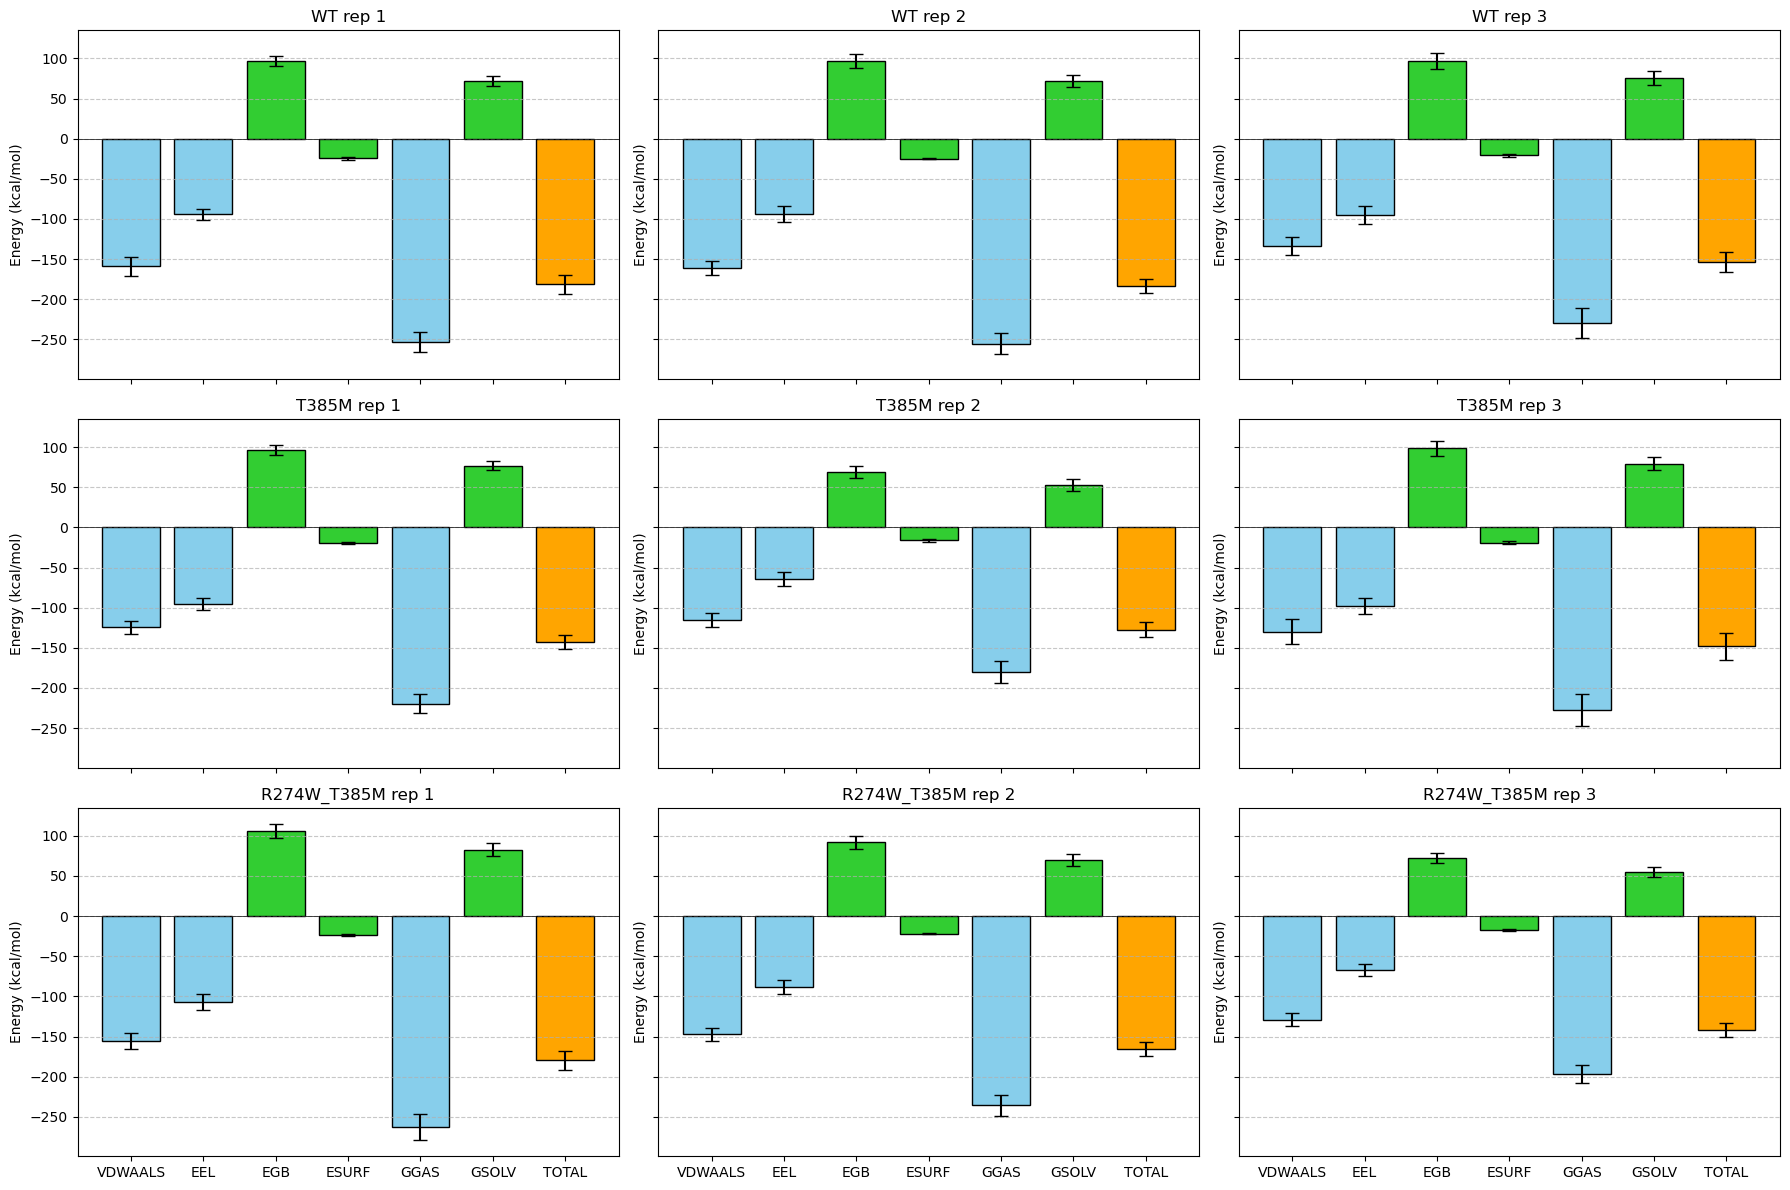

In [9]:

# Find global min and max
all_delta = []
for mut in summary_delta:
    for rep_summary in summary_delta[mut]:
        all_delta.append(rep_summary)

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharey=True, sharex=True)
flat_axes = axes.flatten()

all_delta_plots = []
i = 0
for mut in summary_delta:
    for rep,rep_summary in enumerate(summary_delta[mut]):
        all_delta_plots.append((rep_summary.transpose(), flat_axes[i], f'{mut} rep {rep+1}'))
        i += 1

for df, ax, title in all_delta_plots:
    ax.bar(df.index.astype(str), df['mean'], yerr=df['std'], capsize=5, 
           color=['skyblue', 'skyblue', 'limegreen', 'limegreen', 'skyblue', 'limegreen', 'orange'], edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

### By mutation (combining replicates)

In [10]:
def combine_delta(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        means = [df.loc['mean', col] for df in dfs]
        stds = [df.loc['std', col] for df in dfs]
        
        # Simple mean 
        combined_mean = np.mean(means)
        
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(summary_delta['WT'][0].columns)
    }, index=['mean', 'std'])
    return combined_df


In [11]:
WT_combined_df = combine_delta(summary_delta['WT'])
T385M_combined_df = combine_delta(summary_delta['T385M'])
R274W_T385M_combined_df = combine_delta(summary_delta['R274W_T385M'])

In [12]:
WT_combined_df 

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-151.520898,-94.389035,96.430915,-23.332345,-245.910073,73.098619,-172.811404
std,10.359193,9.342349,8.352273,1.667429,15.058815,7.481464,11.338232


In [13]:
T385M_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-123.323190,-85.811826,87.987488,-18.343609,-209.135003,69.643992,-139.491154
std,11.191221,9.044900,8.009519,1.692996,15.440395,7.212988,11.990987


In [14]:
R274W_T385M_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-143.954355,-87.733287,90.202937,-20.968253,-231.687808,69.234621,-162.453273
std,8.851550,8.755850,7.832432,1.395525,13.636175,7.095816,9.656206


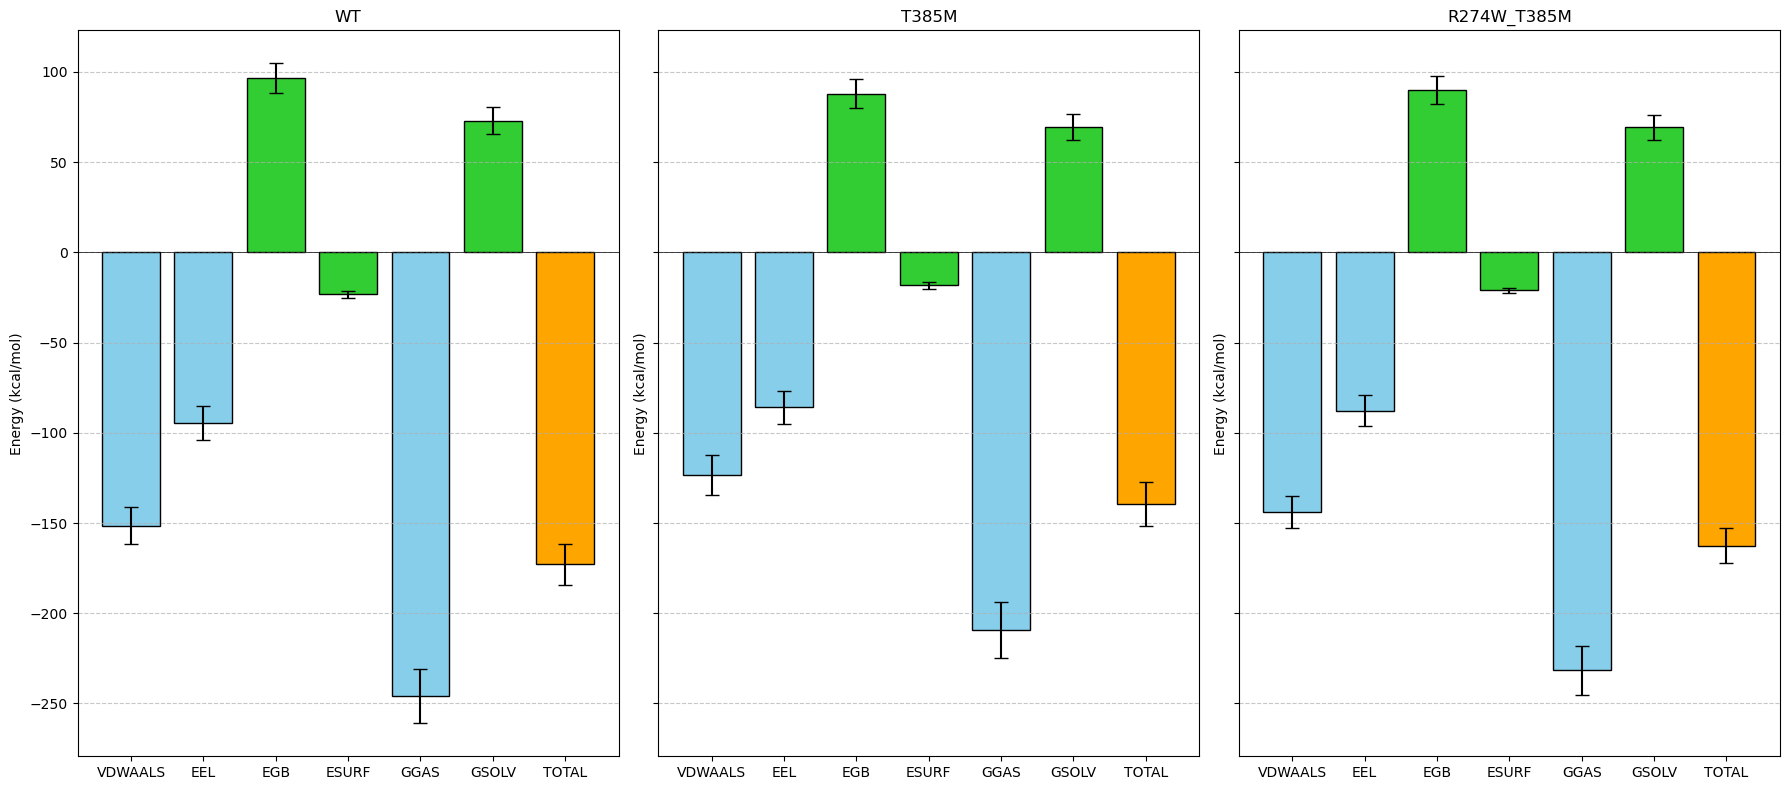

In [15]:

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True, sharex=True)
flat_axes = axes.flatten()

muts = ['WT', 'T385M', 'R274W_T385M']
for i, df in enumerate([WT_combined_df, T385M_combined_df, R274W_T385M_combined_df]):
    ax = flat_axes[i]
    df = df.transpose()
    ax.bar(df.index.astype(str), df['mean'], yerr=df['std'], capsize=5, 
           color=['skyblue', 'skyblue', 'limegreen', 'limegreen', 'skyblue', 'limegreen', 'orange'], edgecolor='black')
    ax.set_title(f'{muts[i]}')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

In [16]:
def df_difference(df1, df2):
    df1_t = df1.transpose()
    df2_t = df2.transpose()
    diff_df = pd.DataFrame({
        'mean': df1_t['mean'] - df2_t['mean'],
        'std': np.sqrt((df1_t['std']**2 + df2_t['std']**2) / 2)  # Pooled standard deviation
    }, index=df1_t.index)
    return diff_df

In [17]:
def plot_comparison(df1, name1, df2, name2):
    df1_t = df1.transpose()
    df2_t = df2.transpose()

    # Verify that dfs have the same index
    if not df1_t.index.equals(df2_t.index):
        raise ValueError("Indices of the dataframes to compare do not match!")

    diff_df = df_difference(df1, df2)

    fig, ax = plt.subplots(figsize=(10, 6))

    labels = df1_t.index  
    x = np.arange(len(labels))  # Positions for bar groups
    width = 0.25

    # Plot WT bars
    ax.bar(x - width, df1_t['mean'], width, yerr=df1_t['std'], 
        capsize=5, color='skyblue', edgecolor='black', label=name1)

    # Plot T385M bars
    ax.bar(x, df2_t['mean'], width, yerr=df2_t['std'], 
        capsize=5, color='orange', edgecolor='black', label=name2)
    # Plot difference (WT - T385M) bars
    ax.bar(x + width, diff_df['mean'], width, yerr=diff_df['std'], 
        capsize=5, color='limegreen', edgecolor='black', label=f'{name1} - {name2}')

    ax.set_title(f'{name1} vs {name2} Energy Comparison')
    ax.set_xlabel('Category')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [18]:
def table_comparison(df1, name1, df2, name2):  
    df1_t = df1.transpose()
    df2_t = df2.transpose()

    diff_df = df_difference(df1, df2)

    table_df = pd.DataFrame({
        'Category': df1_t.index,
        f'{name1} Mean (kcal/mol)': df1_t['mean'].round(2),
        f'{name1} Std (kcal/mol)': df1_t['std'].round(2),
        f'{name2} Mean (kcal/mol)': df2_t['mean'].round(2),
        f'{name2} Std (kcal/mol)': df2_t['std'].round(2),
        'Difference Mean (kcal/mol)': diff_df['mean'].round(2),
        'Difference Std (kcal/mol)': diff_df['std'].round(2)
    })
    return table_df

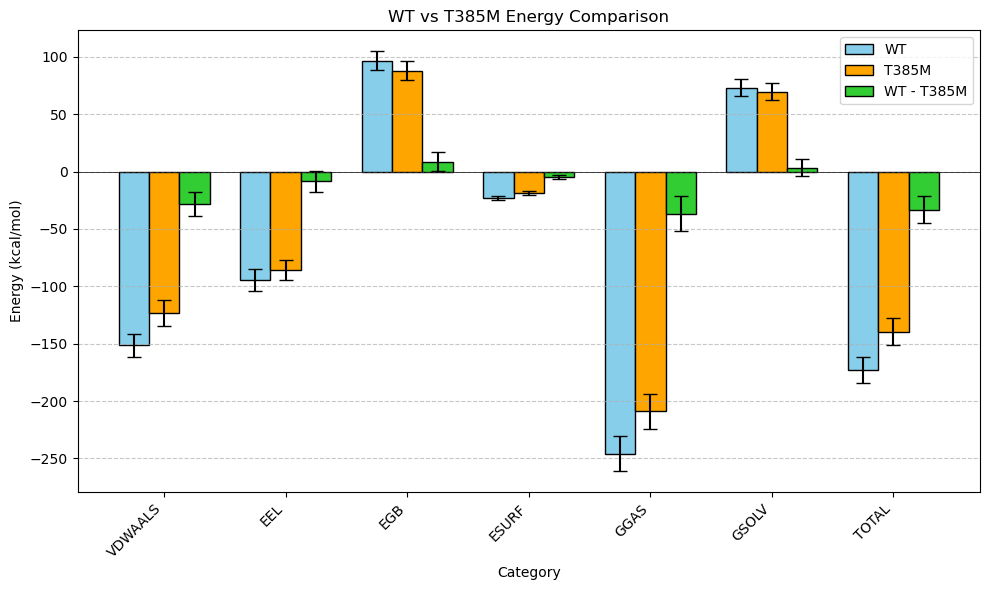

In [19]:
plot_comparison(WT_combined_df, 'WT', T385M_combined_df, 'T385M')

In [20]:
table_comparison(WT_combined_df, 'WT', T385M_combined_df, 'T385M')

,Category,WT Mean (kcal/mol),WT Std (kcal/mol),T385M Mean (kcal/mol),T385M Std (kcal/mol),Difference Mean (kcal/mol),Difference Std (kcal/mol)
VDWAALS,VDWAALS,-151.52,10.36,-123.32,11.19,-28.20,10.78
EEL,EEL,-94.39,9.34,-85.81,9.04,-8.58,9.19
EGB,EGB,96.43,8.35,87.99,8.01,8.44,8.18
ESURF,ESURF,-23.33,1.67,-18.34,1.69,-4.99,1.68
GGAS,GGAS,-245.91,15.06,-209.14,15.44,-36.78,15.25
GSOLV,GSOLV,73.10,7.48,69.64,7.21,3.45,7.35
TOTAL,TOTAL,-172.81,11.34,-139.49,11.99,-33.32,11.67


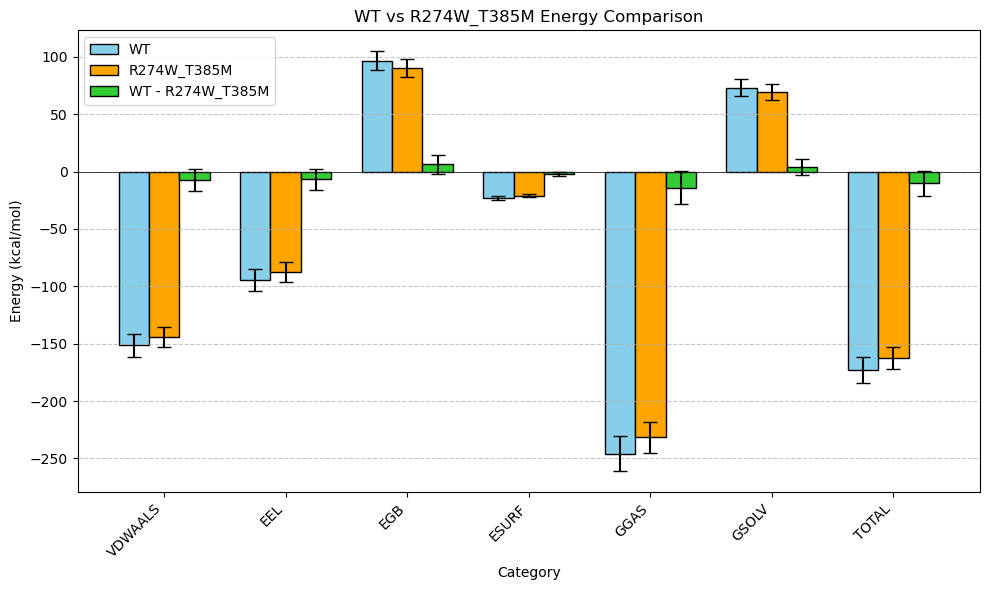

In [21]:
plot_comparison(WT_combined_df, 'WT', R274W_T385M_combined_df, 'R274W_T385M')

In [22]:
table_comparison(WT_combined_df, 'WT', R274W_T385M_combined_df, 'R274W_T385M')

,Category,WT Mean (kcal/mol),WT Std (kcal/mol),R274W_T385M Mean (kcal/mol),R274W_T385M Std (kcal/mol),Difference Mean (kcal/mol),Difference Std (kcal/mol)
VDWAALS,VDWAALS,-151.52,10.36,-143.95,8.85,-7.57,9.63
EEL,EEL,-94.39,9.34,-87.73,8.76,-6.66,9.05
EGB,EGB,96.43,8.35,90.20,7.83,6.23,8.10
ESURF,ESURF,-23.33,1.67,-20.97,1.40,-2.36,1.54
GGAS,GGAS,-245.91,15.06,-231.69,13.64,-14.22,14.37
GSOLV,GSOLV,73.10,7.48,69.23,7.10,3.86,7.29
TOTAL,TOTAL,-172.81,11.34,-162.45,9.66,-10.36,10.53


## Residue decomposition

### Load data

In [23]:
def load_decompenergy(mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = f'../../data/1YVL_noNTD/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY_DECOMP.csv'
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the start and end indices for the section
        start_idx = None
        end_idx = None
        for i, line in enumerate(lines):
            line_clean = line.strip()
            if "DELTAS:" in line_clean:
                start_idx = i + 2  # Skip "DELTAS:" and "Total Decomposition Contribution (TDC)"
                continue
            if start_idx is not None and "Sidechain Decomposition Contribution" in line_clean:
                end_idx = i  
                break

        # Extract the lines between start_idx and end_idx
        data_lines = lines[start_idx:end_idx]
        data_string = ''.join(data_lines)

        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)

    return dfs

In [24]:
WT_decomp_dfs = load_decompenergy('WT')
T385M_decomp_dfs = load_decompenergy('T385M')
R274W_T385M_decomp_dfs = load_decompenergy('R274W_T385M')

In [25]:
WT_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,R:A:MET:21,0.0,-0.36,-0.07,0.09,-0.13,-0.47
1,1000,R:A:ILE:23,0.0,-0.09,-0.07,0.06,0.00,-0.09
2,1000,R:A:GLU:24,0.0,0.37,-1.83,1.92,-0.33,0.13
3,1000,R:A:HIE:25,0.0,-0.55,-0.05,0.11,-0.14,-0.62
4,1000,R:A:ILE:27,0.0,-0.90,-0.23,0.20,-0.06,-0.98


Break down the residue identifiers and adjust the residue numbers.

In [26]:
for df in (WT_decomp_dfs + T385M_decomp_dfs + R274W_T385M_decomp_dfs):
    split_cols = df["Residue"].str.split(":", expand=True)
    df["compound"] = split_cols[0]
    df["chain"] = split_cols[1]
    df["resnm"] = split_cols[2]
    df["resid"] = split_cols[3]
    df["resid_adj"] = np.where(df["chain"].isin(["A", "B"]), (df['resid'].astype(int)+ 133).astype(str), df['resid'])


In [27]:
WT_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid,resid_adj
0,1000,R:A:MET:21,0.0,-0.36,-0.07,0.09,-0.13,-0.47,R,A,MET,21,154
1,1000,R:A:ILE:23,0.0,-0.09,-0.07,0.06,0.00,-0.09,R,A,ILE,23,156
2,1000,R:A:GLU:24,0.0,0.37,-1.83,1.92,-0.33,0.13,R,A,GLU,24,157
3,1000,R:A:HIE:25,0.0,-0.55,-0.05,0.11,-0.14,-0.62,R,A,HIE,25,158
4,1000,R:A:ILE:27,0.0,-0.90,-0.23,0.20,-0.06,-0.98,R,A,ILE,27,160


### WT vs T385M

#### By replicate

In [28]:
def decomp_summary (dfs):
    dfs_decomp_summary = []

    # Energy columns to summarize
    energy_columns = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]

    for df in dfs:
        # Group by residue identifiers
        grouped = df.groupby(['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj'])
        
        # Compute mean, std, and sem for energy columns
        desc = pd.concat([
            grouped[energy_columns].mean().rename(columns=lambda x: f'{x}_mean'),
            grouped[energy_columns].std().rename(columns=lambda x: f'{x}_std'),
        ], axis=1)
        
        # Reset index to make Residue, compound, chain, resnm, resid regular columns
        desc = desc.reset_index()
        
        # Append to summary list
        dfs_decomp_summary.append(desc)
    return dfs_decomp_summary

In [49]:
WT_decomp_dfs[0][WT_decomp_dfs[0]['Residue'] == 'L:B:ARG:141'].sort_values('TOTAL')

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid,resid_adj
29841,1187,L:B:ARG:141,0.0,-0.38,-2.07,1.88,-0.07,-0.64,L,B,ARG,141,274
15531,1097,L:B:ARG:141,0.0,-0.41,-1.60,1.45,-0.06,-0.62,L,B,ARG,141,274
41925,1263,L:B:ARG:141,0.0,-0.41,-2.09,1.90,-0.02,-0.62,L,B,ARG,141,274
115860,1728,L:B:ARG:141,0.0,-0.40,-1.67,1.51,-0.07,-0.62,L,B,ARG,141,274
39381,1247,L:B:ARG:141,0.0,-0.40,-1.47,1.32,-0.06,-0.62,L,B,ARG,141,274
...,...,...,...,...,...,...,...,...,...,...,...,...,...
63390,1398,L:B:ARG:141,0.0,-0.21,-0.08,0.05,0.00,-0.23,L,B,ARG,141,274
103458,1650,L:B:ARG:141,0.0,-0.20,-0.25,0.23,0.00,-0.23,L,B,ARG,141,274
86604,1544,L:B:ARG:141,0.0,-0.20,0.12,-0.14,0.00,-0.22,L,B,ARG,141,274
58620,1368,L:B:ARG:141,0.0,-0.20,-0.12,0.10,0.00,-0.22,L,B,ARG,141,274


In [ ]:
# Mean of TOTAL_mean for resnm ARG resid 141 chain B
WT1_filtered = WT_decomp_dfs[0][WT_decomp_dfs[0]['Residue'] == 'L:B:ARG:141']

WT1_grouped = WT1_filtered.groupby(
    ['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj']
)


In [43]:
WT1_grouped['TOTAL'].mean()

Series([], Name: TOTAL, dtype: float64)

In [142]:
WT_decomp_summary = decomp_summary(WT_decomp_dfs)
T385M_decomp_summary = decomp_summary(T385M_decomp_dfs)
R274W_T385M_decomp_summary = decomp_summary(R274W_T385M_decomp_dfs)

In [143]:
WT_decomp_summary[0].head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,Electrostatic_mean,Polar Solvation_mean,Non-Polar Solv._mean,TOTAL_mean,van der Waals_std,Electrostatic_std,Polar Solvation_std,Non-Polar Solv._std,TOTAL_std
0,L:B:ALA:268,L,B,ALA,268,401,-0.071028,0.018313,-0.003743,0.000000,-0.056337,0.009682,0.033537,0.030102,0.000000,0.012341
1,L:B:ALA:269,L,B,ALA,269,402,-0.083922,-0.170878,0.165200,0.000000,-0.089701,0.012850,0.043088,0.039234,0.000000,0.014983
2,L:B:ARG:141,L,B,ARG,141,274,-0.268234,-0.766277,0.685170,-0.003024,-0.352455,0.044441,0.379033,0.353153,0.010565,0.067839
3,L:B:ARG:272,L,B,ARG,272,405,-1.581816,-4.835689,4.414182,-0.318204,-2.321647,1.119991,1.306219,1.115045,0.148277,1.208340
4,L:B:ARG:47,L,B,ARG,47,180,-0.184850,3.235968,-3.145898,-0.003972,-0.098543,0.077921,0.389456,0.362404,0.015784,0.085369


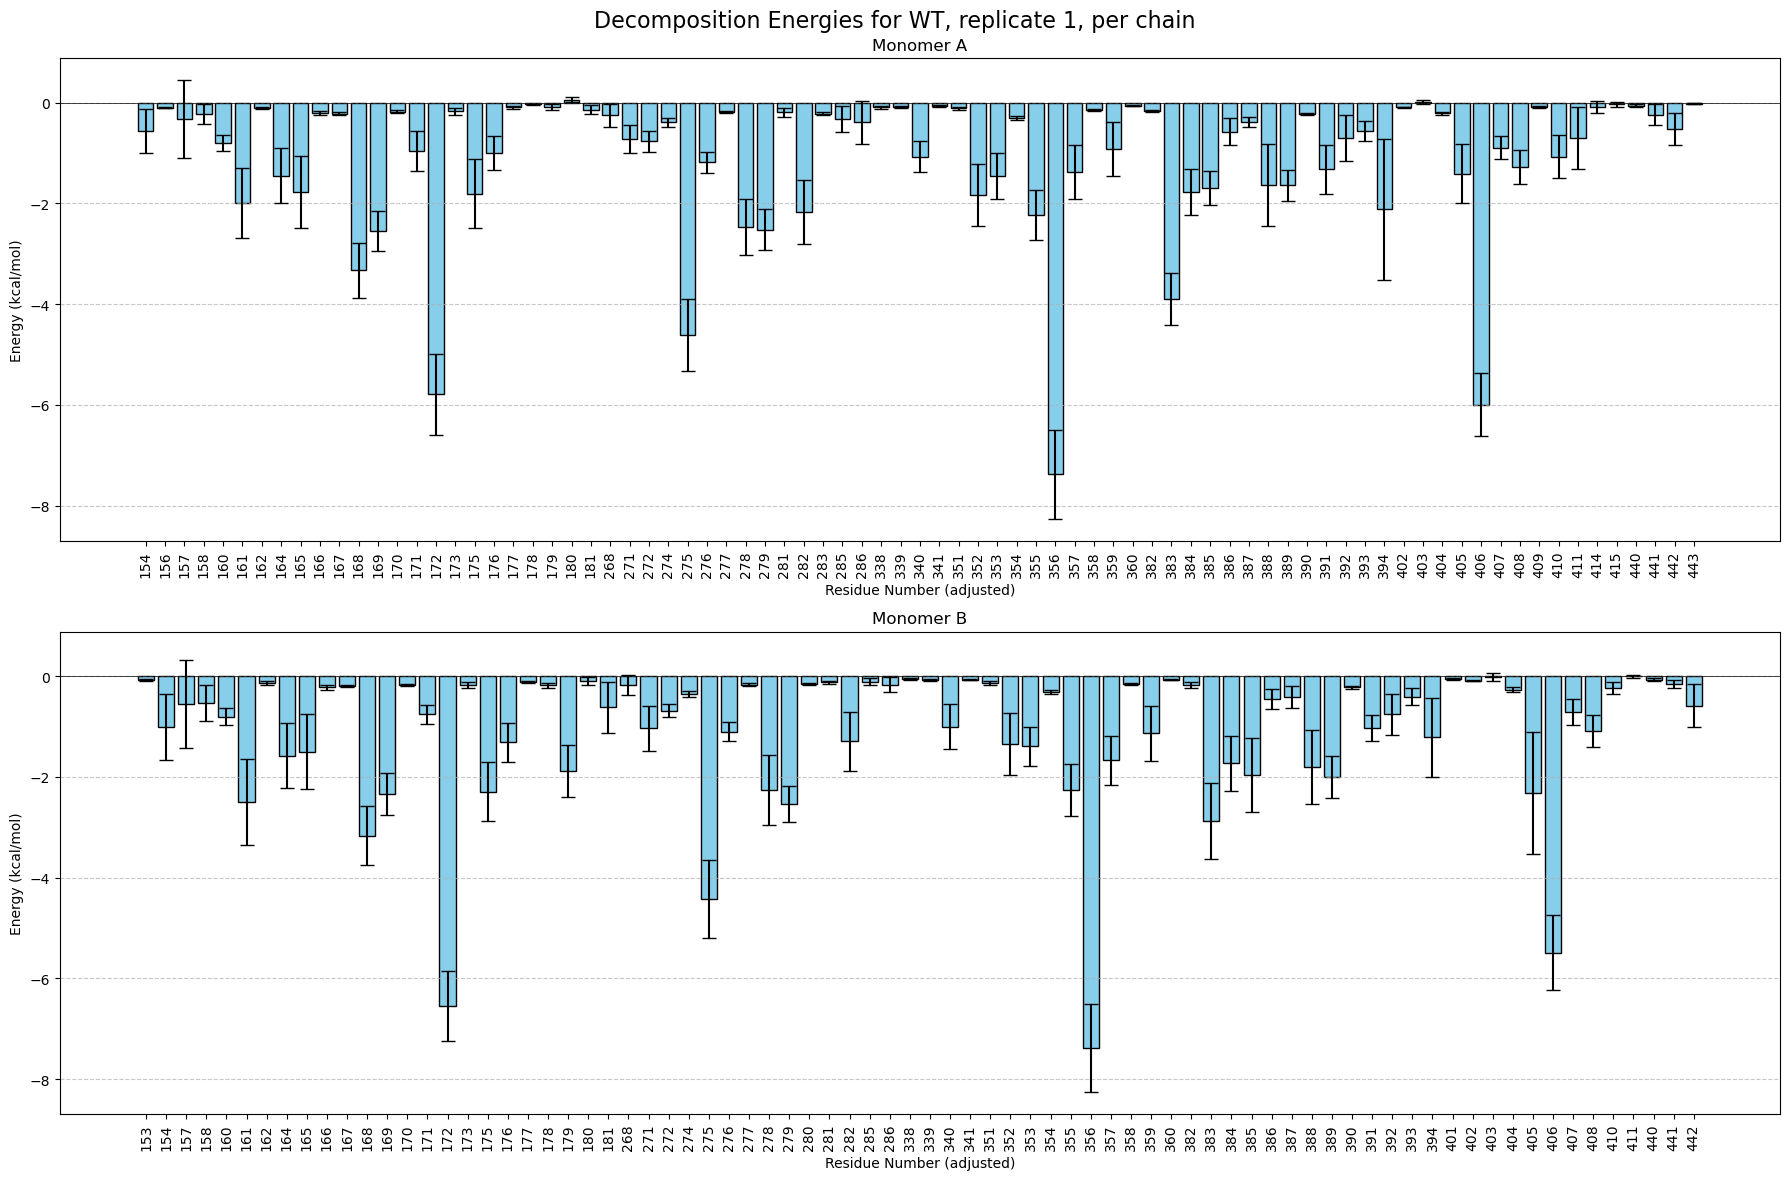

In [144]:
df_chainA = WT_decomp_summary[0][WT_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_chainB = WT_decomp_summary[0][WT_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharey=True)
ax1, ax2 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B')
]

for df, ax, title in plots:
    ax.bar(df["resid_adj"], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

In [145]:
WT_decomp_summary[0][WT_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique() 

array(['154', '156', '157', '158', '160', '161', '162', '164', '165',
       '166', '167', '168', '169', '170', '171', '172', '173', '175',
       '176', '177', '178', '179', '180', '181', '268', '271', '272',
       '274', '275', '276', '277', '278', '279', '281', '282', '283',
       '285', '286', '338', '339', '340', '341', '351', '352', '353',
       '354', '355', '356', '357', '358', '359', '360', '382', '383',
       '384', '385', '386', '387', '388', '389', '390', '391', '392',
       '393', '394', '402', '403', '404', '405', '406', '407', '408',
       '409', '410', '411', '414', '415', '440', '441', '442', '443'],
      dtype=object)

In [146]:
WT_decomp_summary[0][WT_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array(['153', '154', '157', '158', '160', '161', '162', '164', '165',
       '166', '167', '168', '169', '170', '171', '172', '173', '175',
       '176', '177', '178', '179', '180', '181', '268', '271', '272',
       '274', '275', '276', '277', '278', '279', '280', '281', '282',
       '285', '286', '338', '339', '340', '341', '351', '352', '353',
       '354', '355', '356', '357', '358', '359', '360', '382', '383',
       '384', '385', '386', '387', '388', '389', '390', '391', '392',
       '393', '394', '401', '402', '403', '404', '405', '406', '407',
       '408', '410', '411', '440', '441', '442'], dtype=object)

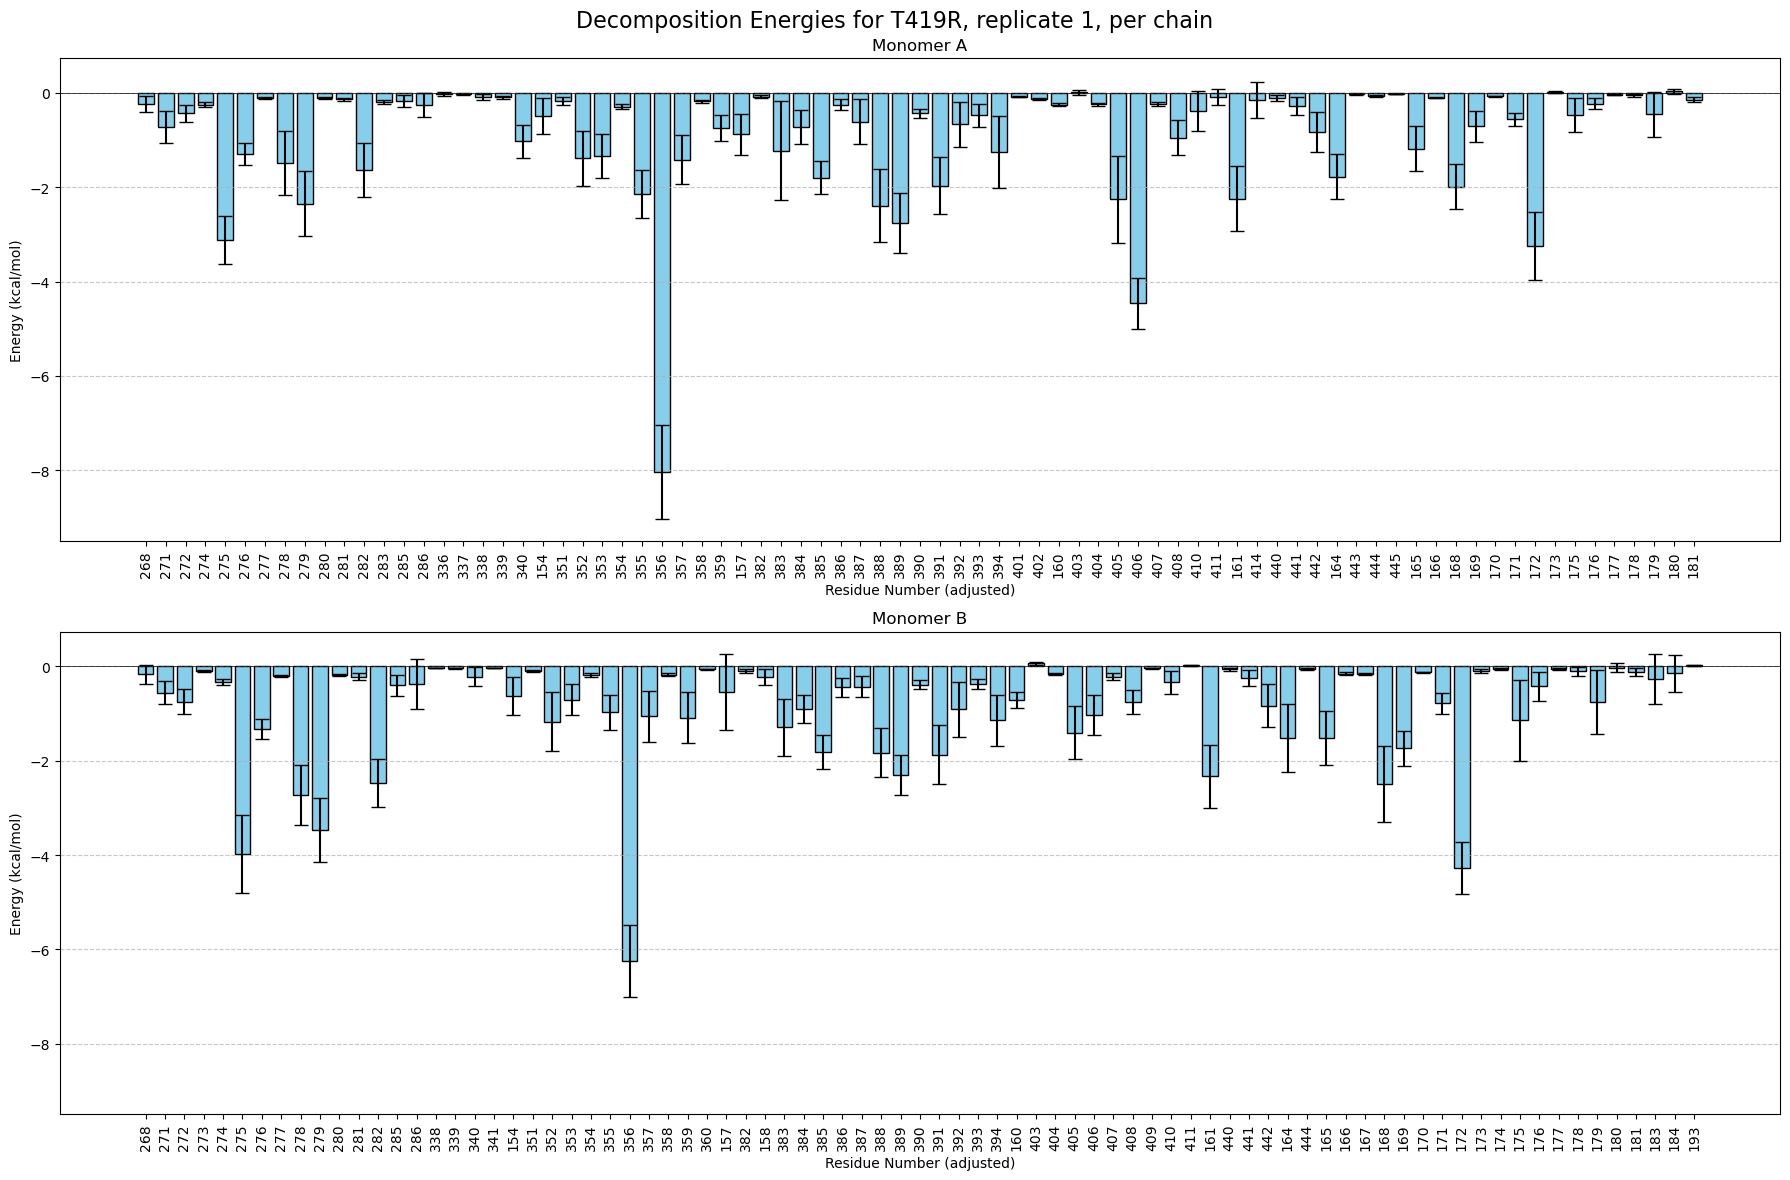

In [147]:
df_chainA = T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
df_chainB = T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)


fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharey=True)
ax1, ax2 = axes.flatten()
plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B')
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for T419R, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

#### By mutation (combining replicates)

In [148]:
def combine_decomp(dfs):
    
    df = pd.concat(dfs)

    energy_terms = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]
    
    # Columns for means and standard deviations
    mean_cols = [f"{term}_mean" for term in energy_terms]
    std_cols = [f"{term}_std" for term in energy_terms]
    
    # Group by residue identifiers
    group_cols = ['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj']
    df_grouped = df.groupby(group_cols)
    
    result_data = []
    
    # Process each group (residue)
    for name, group in df_grouped:
        # Dictionary to store results for this group
        group_result = dict(zip(group_cols, name))
        
        # Calculate mean and pooled std for each energy term
        for mean_col, std_col in zip(mean_cols, std_cols):
            # Mean
            combined_mean = group[mean_col].mean()
            
            # Pooled standard deviation
            stds = group[std_col]
            variances = [s**2 for s in stds]
            pooled_variance = np.mean(variances)  # Average variances
            pooled_std = np.sqrt(pooled_variance) if pooled_variance > 0 else 0.0
            
            group_result[mean_col] = combined_mean
            group_result[std_col] = pooled_std
        
        result_data.append(group_result)
    
    combined_df = pd.DataFrame(result_data)
    
    # Reorder columns to match input structure
    output_cols = group_cols + [col for term in energy_terms for col in [f"{term}_mean", f"{term}_std"]]
    combined_df = combined_df[output_cols]
    
    return combined_df

In [149]:
WT_decomp_combined_df = combine_decomp(WT_decomp_summary)
T385M_decomp_combined_df = combine_decomp(T385M_decomp_summary)
R274W_T385M_decomp_combined_df = combine_decomp(R274W_T385M_decomp_summary)

In [150]:
WT_decomp_combined_df.head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,van der Waals_std,Electrostatic_mean,Electrostatic_std,Polar Solvation_mean,Polar Solvation_std,Non-Polar Solv._mean,Non-Polar Solv._std,TOTAL_mean,TOTAL_std
0,L:B:ALA:268,L,B,ALA,268,401,-0.071028,0.009682,0.018313,0.033537,-0.003743,0.030102,0.000000,0.000000,-0.056337,0.012341
1,L:B:ALA:269,L,B,ALA,269,402,-0.088857,0.014182,-0.169586,0.042655,0.164062,0.038286,-0.000010,0.000316,-0.094371,0.014996
2,L:B:ARG:141,L,B,ARG,141,274,-0.268234,0.044441,-0.766277,0.379033,0.685170,0.353153,-0.003024,0.010565,-0.352455,0.067839
3,L:B:ARG:272,L,B,ARG,272,405,-1.521051,0.963222,-5.088666,1.282233,4.650429,1.080021,-0.345459,0.135972,-2.304764,1.011997
4,L:B:ARG:47,L,B,ARG,47,180,-0.402731,0.370993,3.589381,0.457039,-3.447638,0.407256,-0.034963,0.056221,-0.295898,0.372784


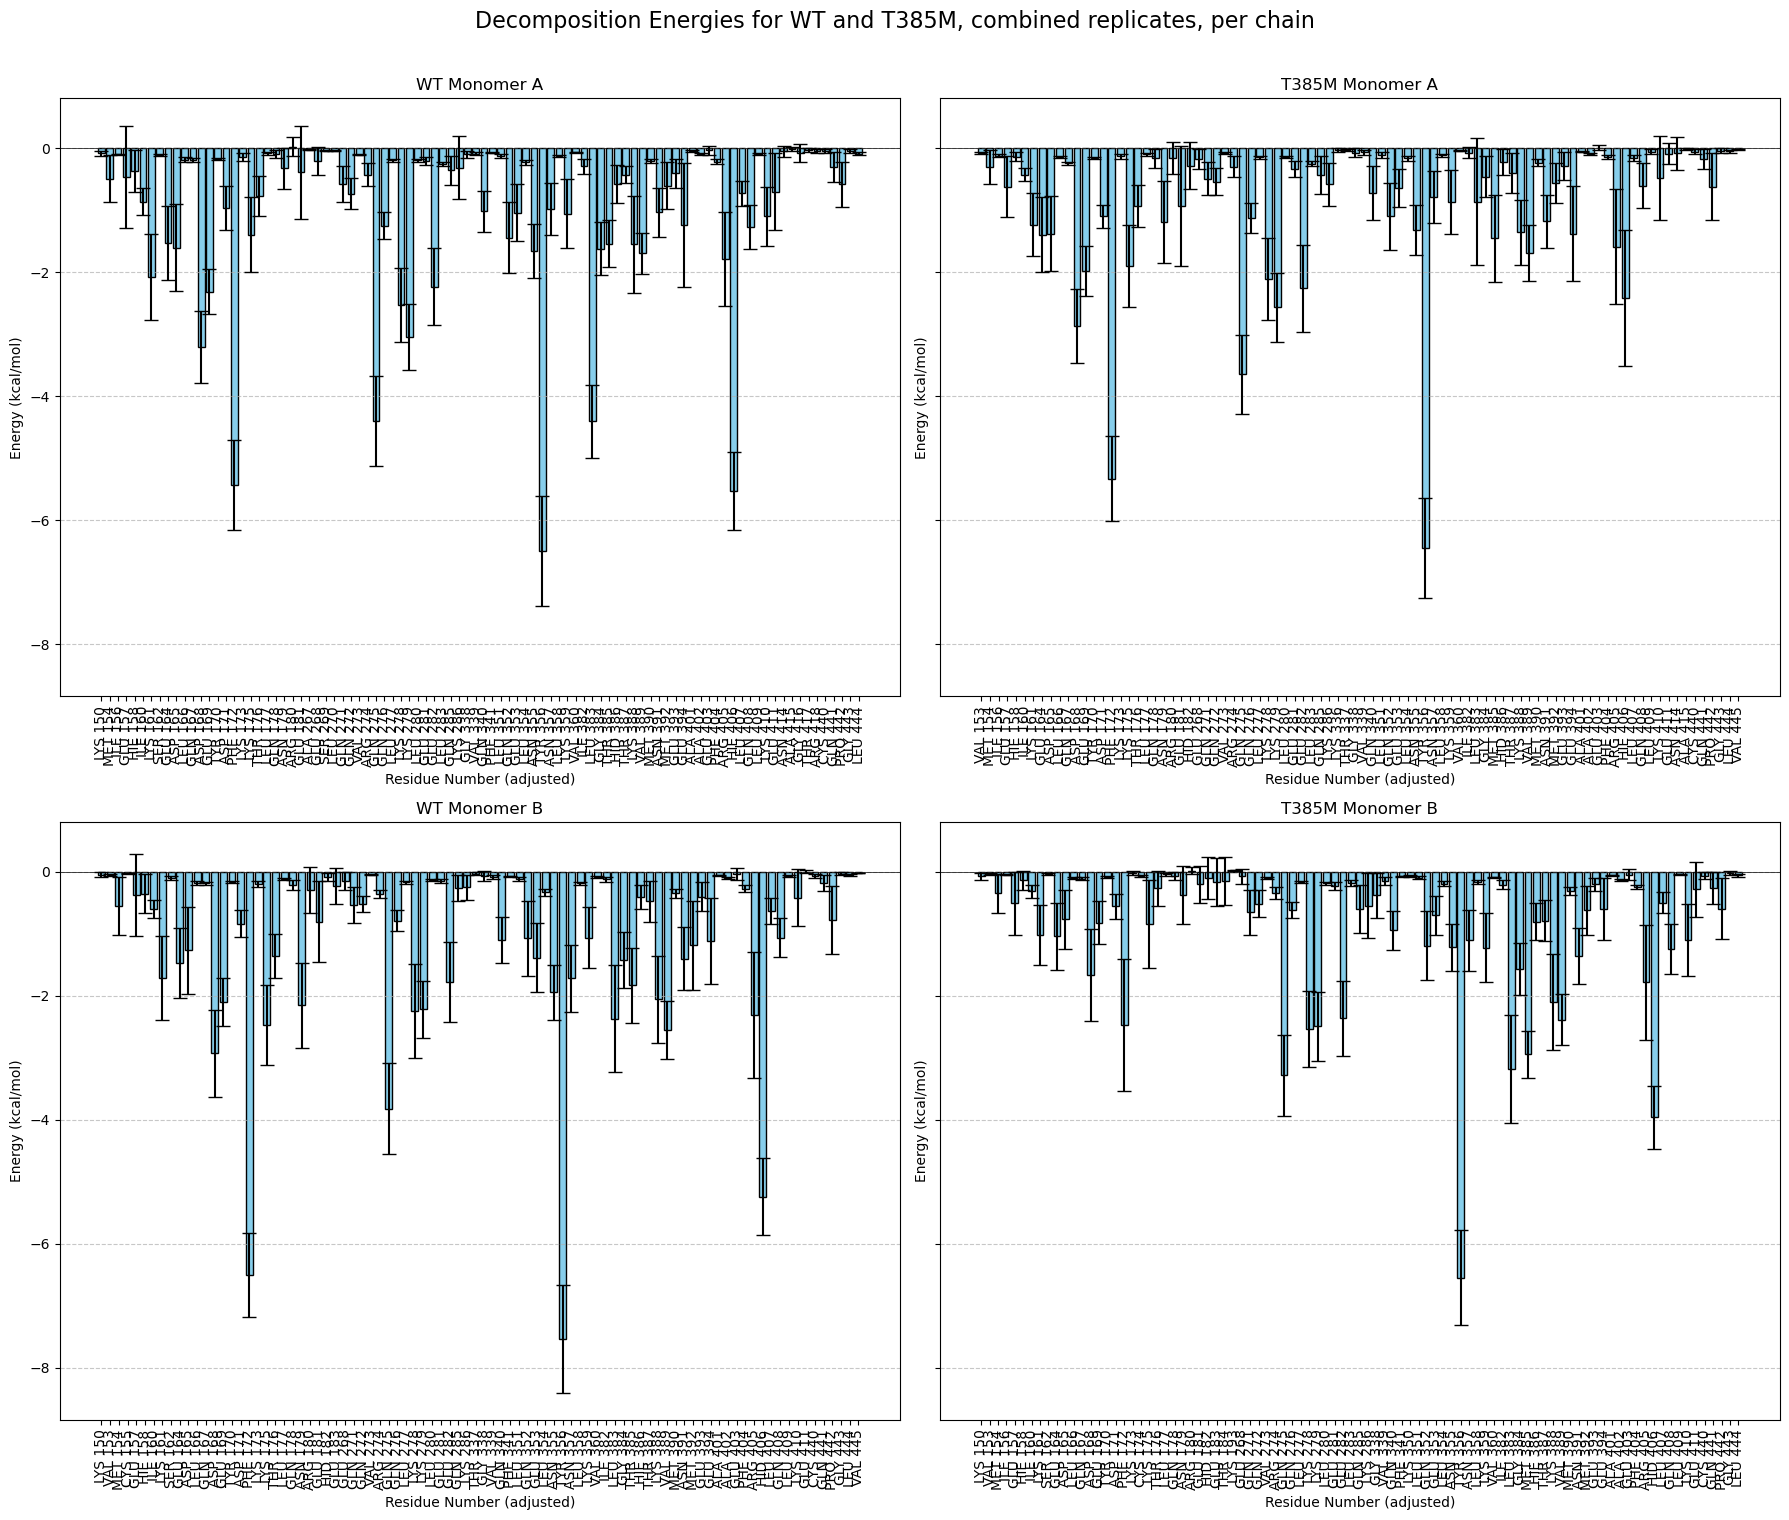

In [151]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoA = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoB = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)


fig, axes = plt.subplots(2, 2, figsize=(18, 15), sharey=True)
ax1, ax2, ax3, ax4= axes.flatten()

plots = [
    (df_WT_monoA, ax1, 'WT Monomer A'),
    (df_T385M_monoA, ax2, 'T385M Monomer A'),
    (df_WT_monoB, ax3, 'WT Monomer B'),
    (df_T385M_monoB, ax4, 'T385M Monomer B')
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(df['resnm'], df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and T385M, combined replicates, per chain', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

Zoom in on the mutated residue.

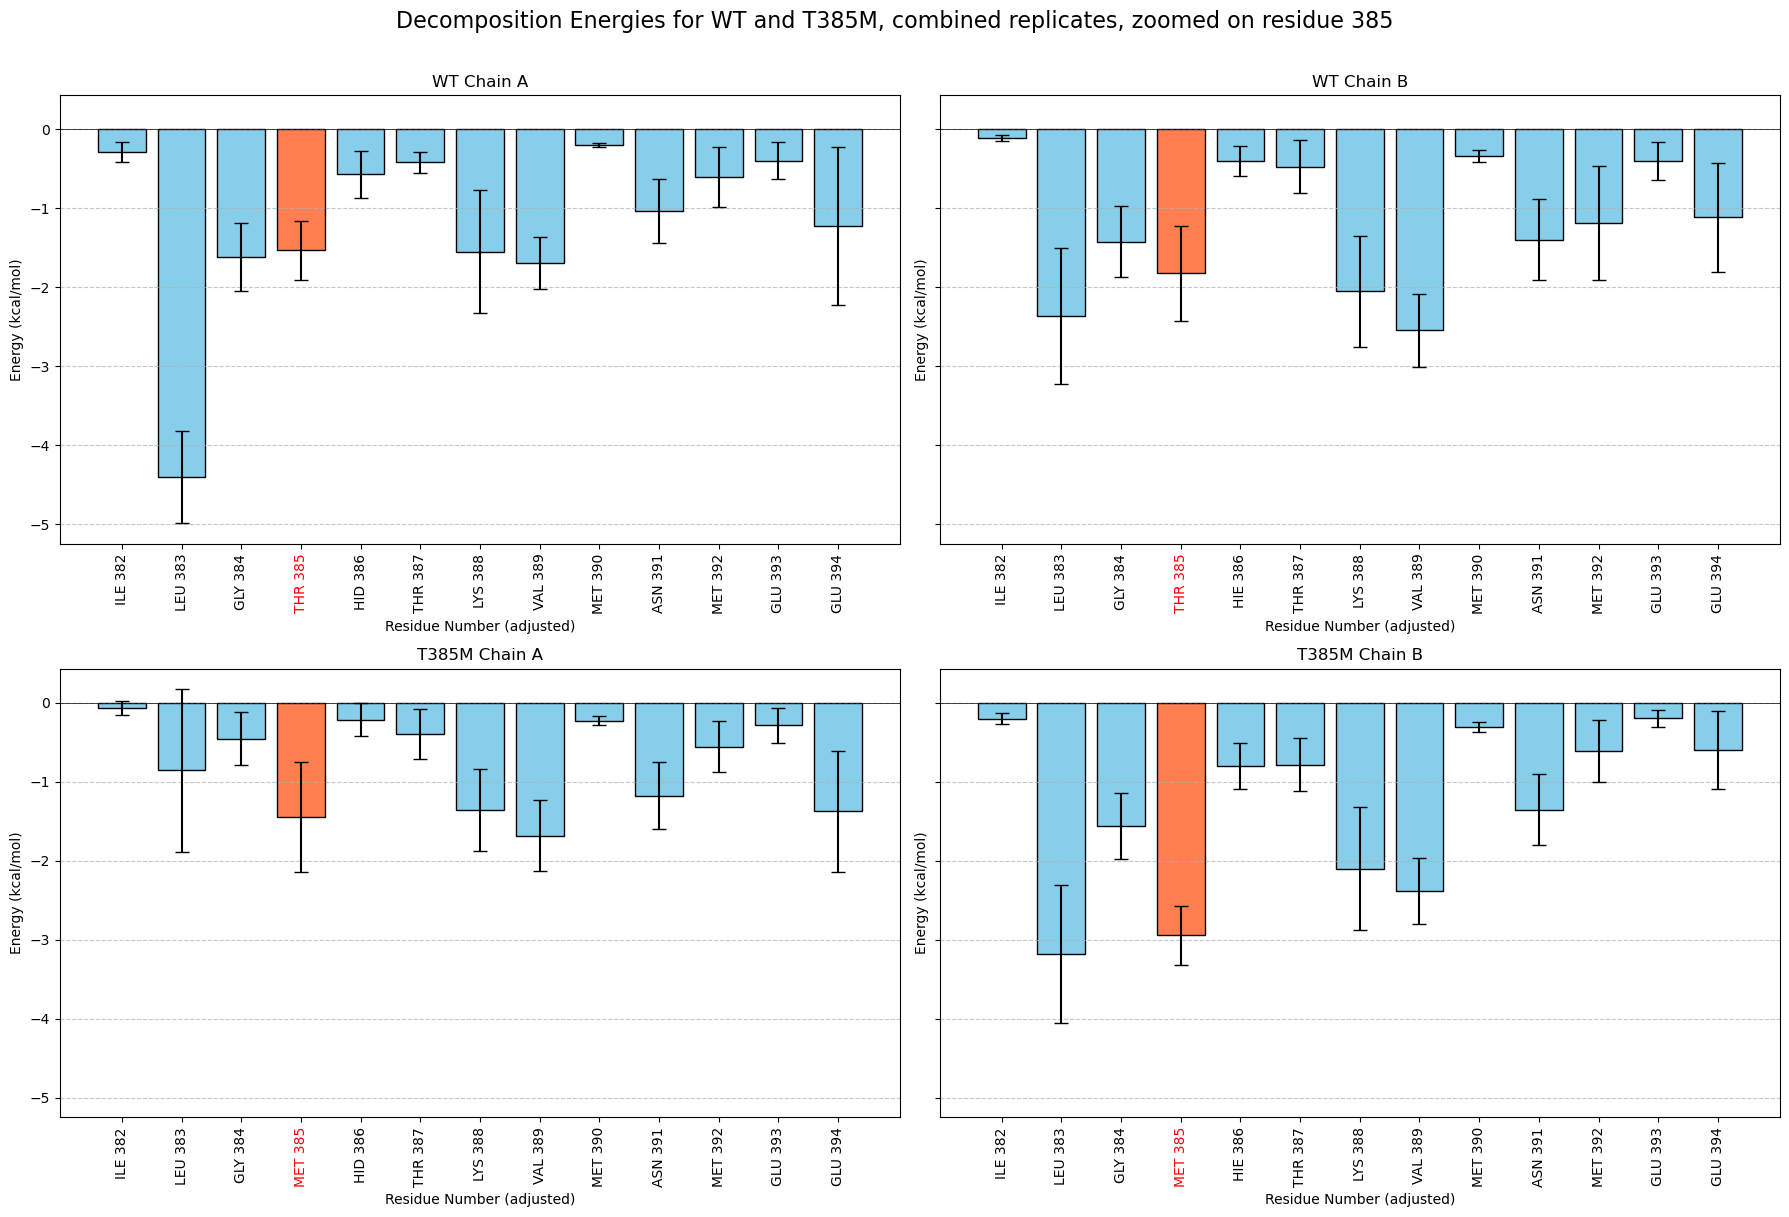

In [210]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoA = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoB = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_T385M_monoA, ax3, 'T385M Chain A'),
    (df_T385M_monoB, ax4, 'T385M Chain B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 375) & (df['resid_adj'].astype(int) < 395)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    # color the mutation site red
    colors = ['red' if int(resid) == 385 else 'black' for resid in filtered_df['resid_adj']]
    for ticklabel, color in zip(ax.get_xticklabels(), colors):
        ticklabel.set_color(color)
    # color de mutation bar red
    for bar, resid in zip(ax.patches, filtered_df['resid_adj']):
        if int(resid) == 385:
            bar.set_color('coral')
            bar.set_edgecolor('black')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and T385M, combined replicates, zoomed on residue 385', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

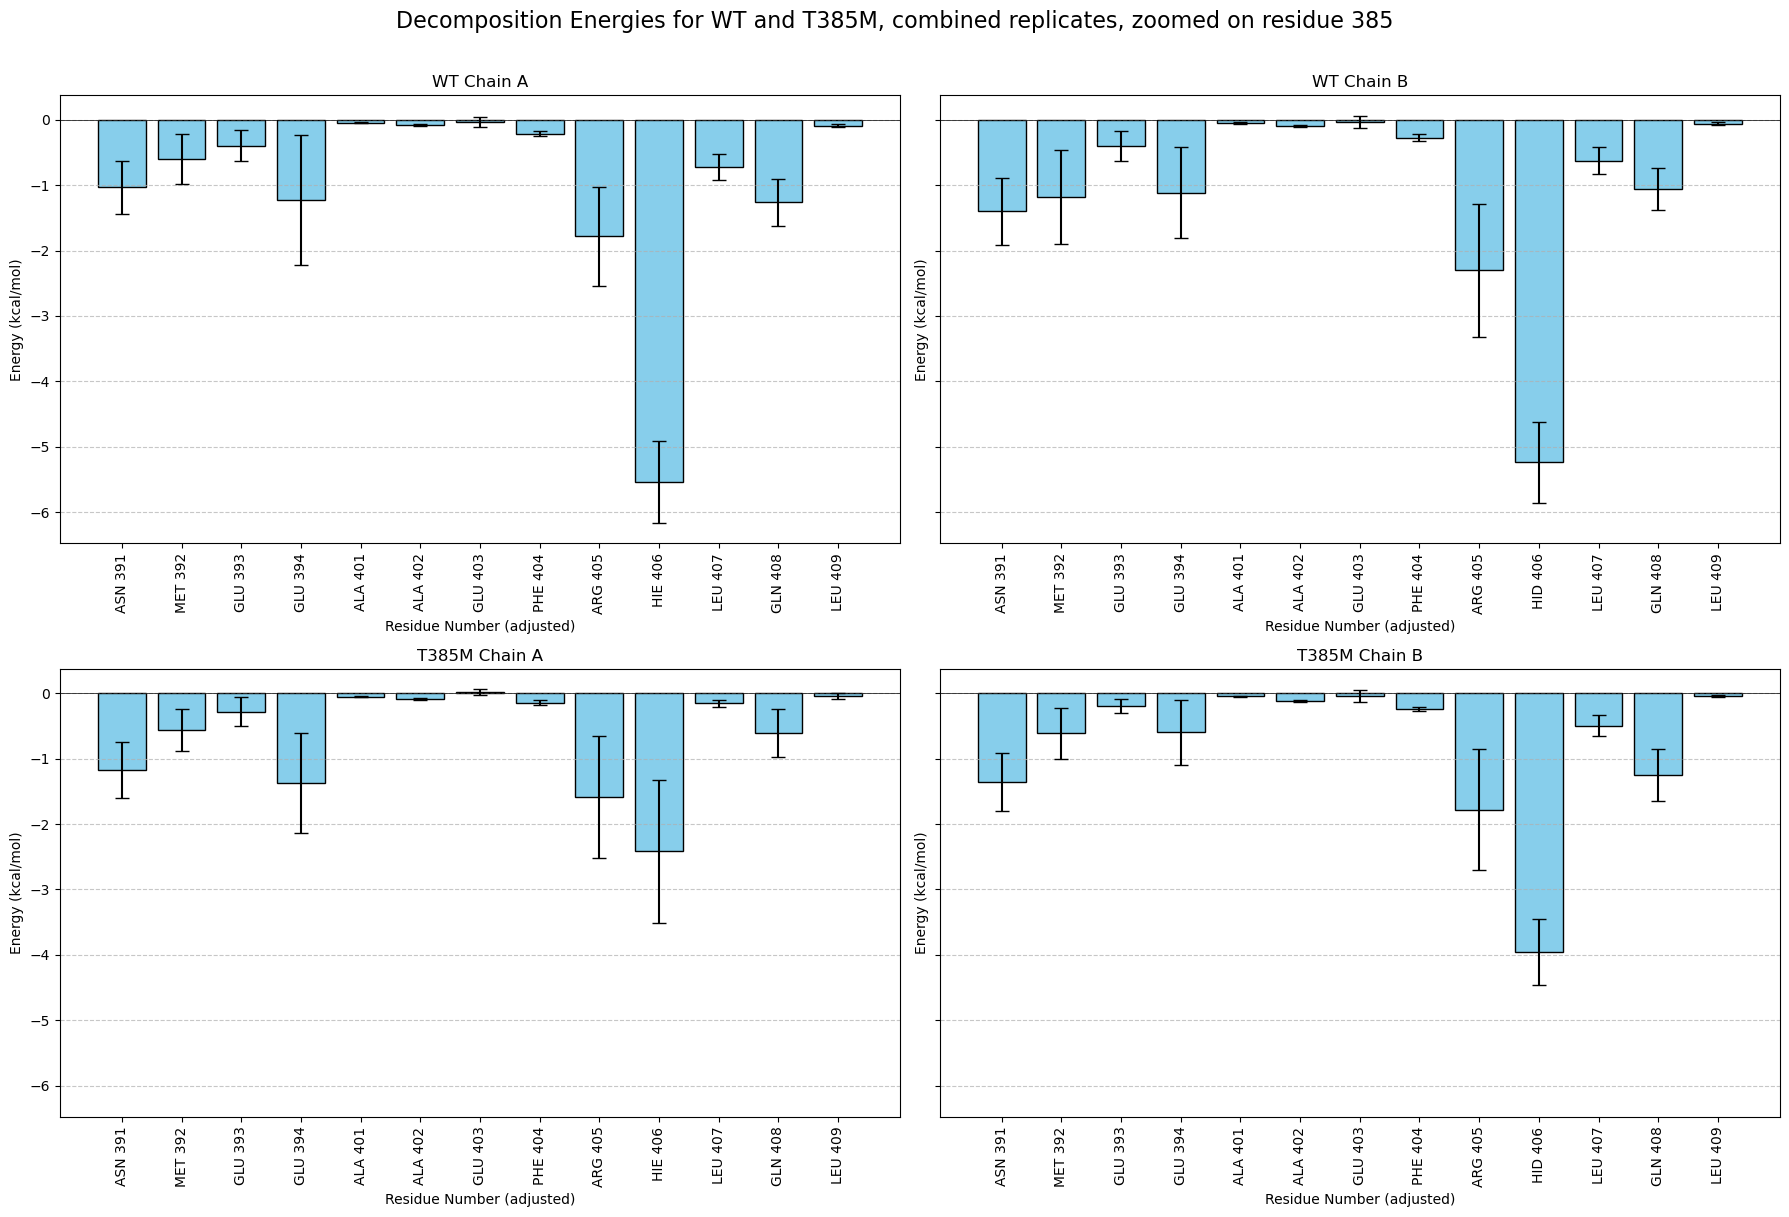

In [175]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoA = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoB = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_T385M_monoA, ax3, 'T385M Chain A'),
    (df_T385M_monoB, ax4, 'T385M Chain B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 390) & (df['resid_adj'].astype(int) < 410)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    # color the mutation site red
    colors = ['red' if int(resid) == 385 else 'black' for resid in filtered_df['resid_adj']]
    for ticklabel, color in zip(ax.get_xticklabels(), colors):
        ticklabel.set_color(color)
    # color de mutation bar red
    for bar, resid in zip(ax.patches, filtered_df['resid_adj']):
        if int(resid) == 385:
            bar.set_color('coral')
            bar.set_edgecolor('black')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and T385M, combined replicates, zoomed on residue 385', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

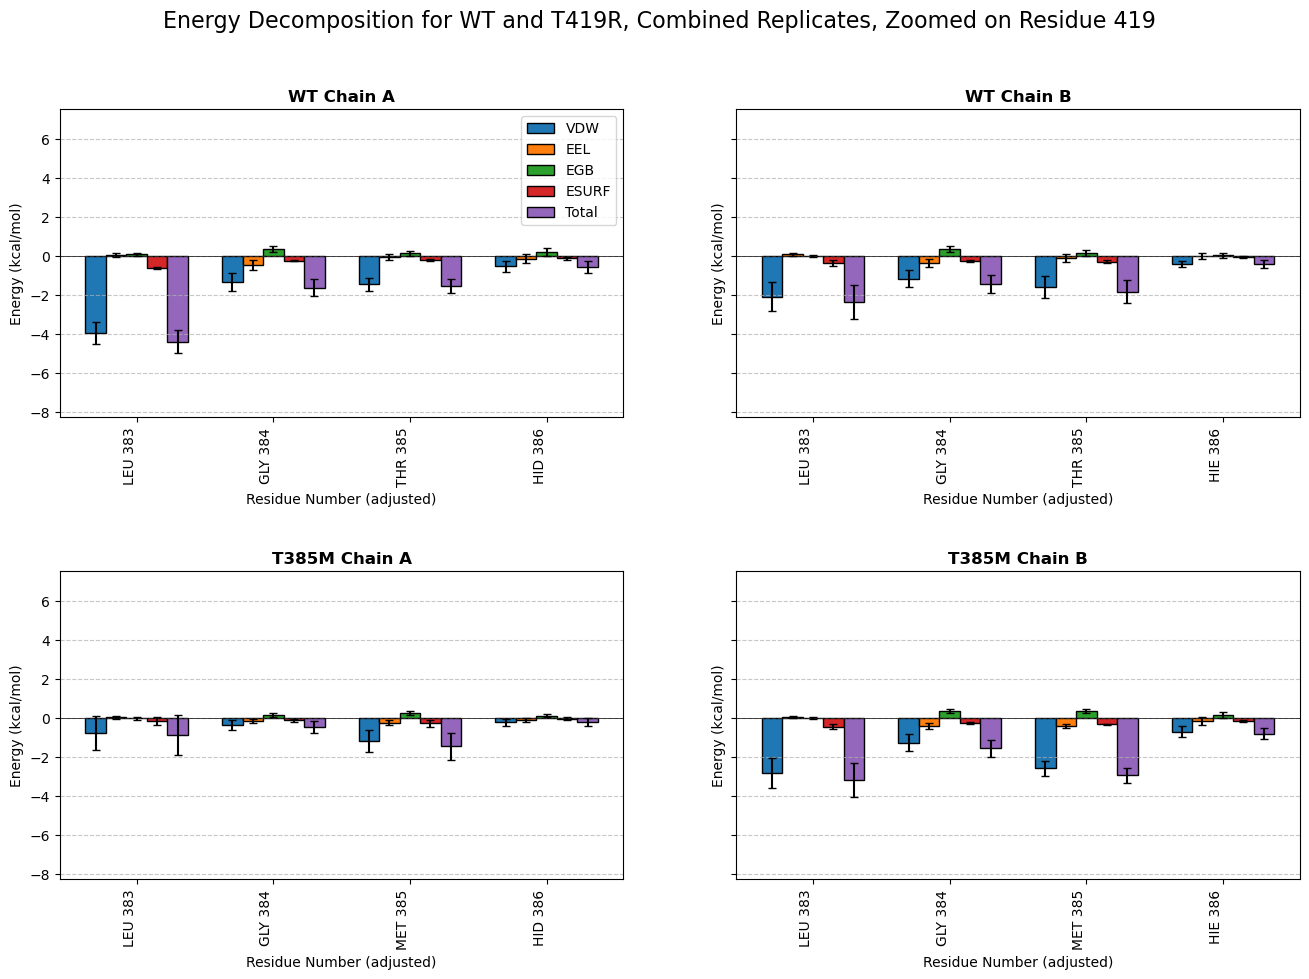

In [166]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoA = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T385M_monoB = T385M_decomp_combined_df[T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Define energy terms and their corresponding std columns
energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_WT_monoA, df_T385M_monoA, df_WT_monoB, df_T385M_monoB]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  # Add 10% buffer
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  # Add 10% buffer

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_T385M_monoA, ax3, 'T385M Chain A'),
    (df_T385M_monoB, ax4, 'T385M Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 380-390
    filtered_df = df[(df['resid_adj'].astype(int) > 382) & (df['resid_adj'].astype(int) < 387)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and T419R, Combined Replicates, Zoomed on Residue 419', fontsize=16)


plt.subplots_adjust(hspace=0.5)
plt.show()

In [180]:
# Merge WT and T419R DataFrames on 'resid_adj' and 'chain' to get common residues
common_df = WT_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean', 'TOTAL_mean']].merge(
    T385M_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean', 'TOTAL_mean']],
    on=['resid_adj', 'chain'],
    suffixes=('_WT', '_T385M')
)

# Calculate the differences (WT - T385M)
common_df['EEL_diff'] = common_df['Electrostatic_mean_WT'] - common_df['Electrostatic_mean_T385M']
common_df['VDW_diff'] = common_df['van der Waals_mean_WT'] - common_df['van der Waals_mean_T385M']
common_df['EGB_diff'] = common_df['Polar Solvation_mean_WT'] - common_df['Polar Solvation_mean_T385M']
common_df['ESURF_diff'] = common_df['Non-Polar Solv._mean_WT'] - common_df['Non-Polar Solv._mean_T385M']
common_df['TOTAL_diff'] = common_df['TOTAL_mean_WT'] - common_df['TOTAL_mean_T385M']

In [195]:
common_df.head()

,Residue_WT,resid_adj,chain,Electrostatic_mean_WT,Polar Solvation_mean_WT,van der Waals_mean_WT,Non-Polar Solv._mean_WT,TOTAL_mean_WT,Residue_T385M,Electrostatic_mean_T385M,Polar Solvation_mean_T385M,van der Waals_mean_T385M,Non-Polar Solv._mean_T385M,TOTAL_mean_T385M,EEL_diff,VDW_diff,EGB_diff,ESURF_diff,TOTAL_diff
0,L:B:ALA:268,401,B,0.018313,-0.003743,-0.071028,0.000000,-0.056337,L:B:ALA:268,0.050539,-0.035160,-0.066347,-0.000040,-0.051028,-0.032226,-0.004681,0.031417,0.000040,-0.005309
1,L:B:ALA:269,402,B,-0.169586,0.164062,-0.088857,-0.000010,-0.094371,L:B:ALA:269,-0.193982,0.190559,-0.120848,-0.000140,-0.124870,0.024396,0.031991,-0.026497,0.000130,0.030499
2,L:B:ARG:141,274,B,-0.766277,0.685170,-0.268234,-0.003024,-0.352455,L:B:ARG:141,-0.624306,0.551277,-0.263004,-0.003553,-0.339586,-0.141971,-0.005230,0.133892,0.000529,-0.012869
3,L:B:ARG:272,405,B,-5.088666,4.650429,-1.521051,-0.345459,-2.304764,L:B:ARG:272,-4.373410,4.019461,-1.181497,-0.246507,-1.782069,-0.715256,-0.339554,0.630968,-0.098952,-0.522695
4,L:B:ARG:47,180,B,3.589381,-3.447638,-0.402731,-0.034963,-0.295898,L:B:ARG:47,3.124088,-3.032418,-0.066810,-0.002931,0.021710,0.465293,-0.335921,-0.415220,-0.032033,-0.317608


Residues not in both dfs

In [181]:
# Perform an outer merge to include all residues and their associated columns
merged_df = WT_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    T385M_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    how='outer',
    indicator=True,
    suffixes=('_WT', '_T385M')
)

# Filter for residues that are only in one DataFrame
non_common_df = merged_df[merged_df['_merge'] != 'both'].copy()

# Create a column to indicate which DataFrame the residue is from
non_common_df['Source'] = non_common_df['_merge'].map({
    'left_only': 'WT',
    'right_only': 'T385M'
})

# Create consolidated columns for the energy terms, prioritizing WT or T385M values
non_common_df['Electrostatic_mean'] = non_common_df['Electrostatic_mean_WT'].fillna(non_common_df['Electrostatic_mean_T385M'])
non_common_df['Polar Solvation_mean'] = non_common_df['Polar Solvation_mean_WT'].fillna(non_common_df['Polar Solvation_mean_T385M'])
non_common_df['van der Waals_mean'] = non_common_df['van der Waals_mean_WT'].fillna(non_common_df['van der Waals_mean_T385M'])
non_common_df['Non-Polar Solv._mean'] = non_common_df['Non-Polar Solv._mean_WT'].fillna(non_common_df['Non-Polar Solv._mean_T385M'])

# Select relevant columns for the final table
result_df = non_common_df[['resid_adj', 'chain', 'Source', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']]

# Print the table
result_df

,resid_adj,chain,Source,Electrostatic_mean,Polar Solvation_mean,van der Waals_mean,Non-Polar Solv._mean
12,155,B,WT,-0.078453,0.078633,-0.018952,0.000000
76,337,B,WT,-0.035988,0.039471,-0.032455,-0.000020
87,445,B,WT,-0.014461,0.015908,-0.019571,0.000000
88,267,A,WT,-0.007365,0.018822,-0.030908,0.000000
94,418,A,WT,-0.691467,0.666577,-0.010449,-0.000210
130,416,A,WT,-0.021826,0.023004,-0.066687,-0.006218
138,270,A,WT,-0.030798,0.042186,-0.047635,0.000000
154,150,A,WT,0.197974,-0.204242,-0.065509,-0.002295
164,341,A,WT,0.122395,-0.098433,-0.090579,0.000000
168,269,A,WT,-0.036477,0.054072,-0.052535,0.000000


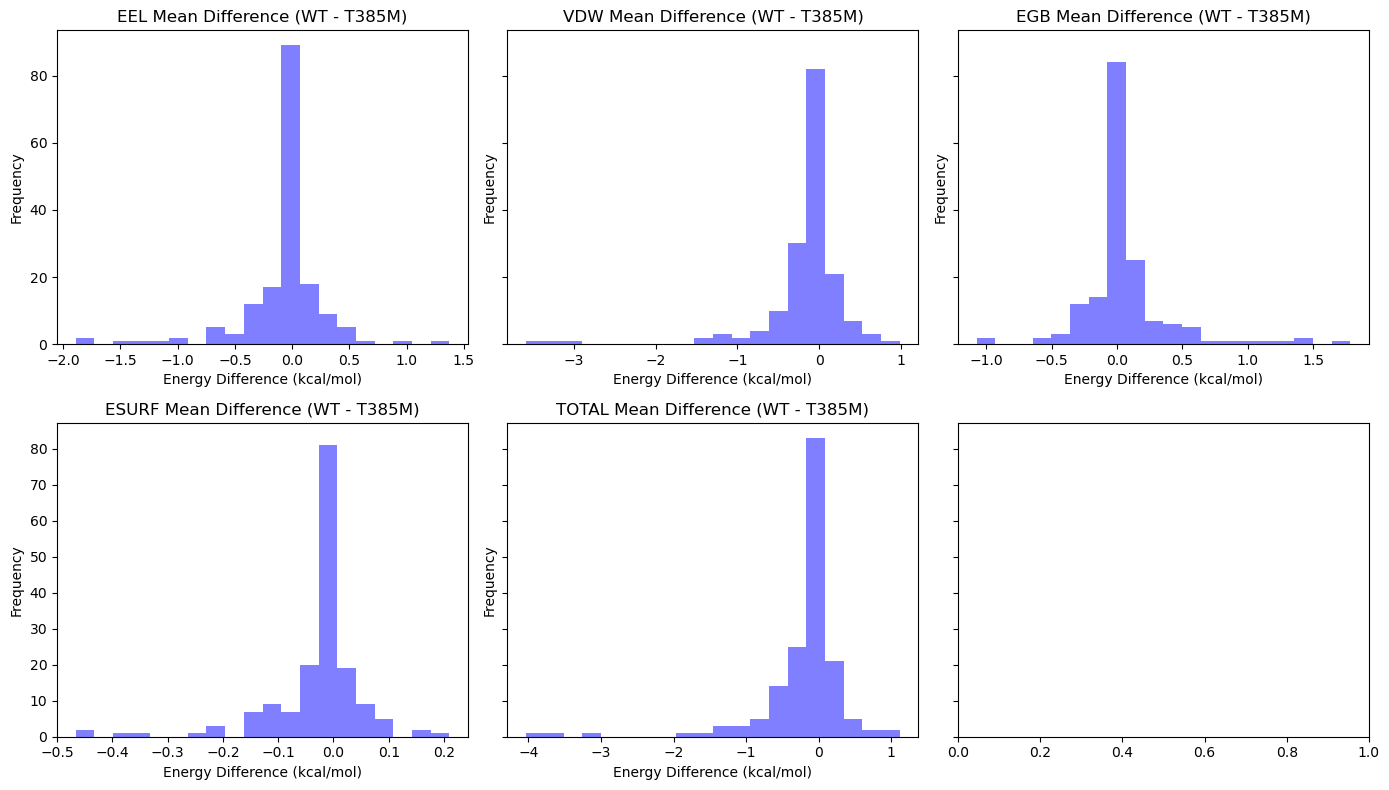

In [184]:
# columns ending in '_diff'
diff_columns = common_df.filter(like='_diff').columns

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey='row', squeeze=False)
axes_flat = axes.flatten()

for i, diff_col in enumerate(diff_columns):
    # Extract the energy term name
    term_name = diff_col.replace('_diff', '')
    ax = axes_flat[i]
    # All residues
    ax.hist(common_df[diff_col], bins=20, alpha=0.5, color='blue')
    ax.set_title(f'{term_name} Mean Difference (WT - T385M)')
    ax.set_xlabel('Energy Difference (kcal/mol)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

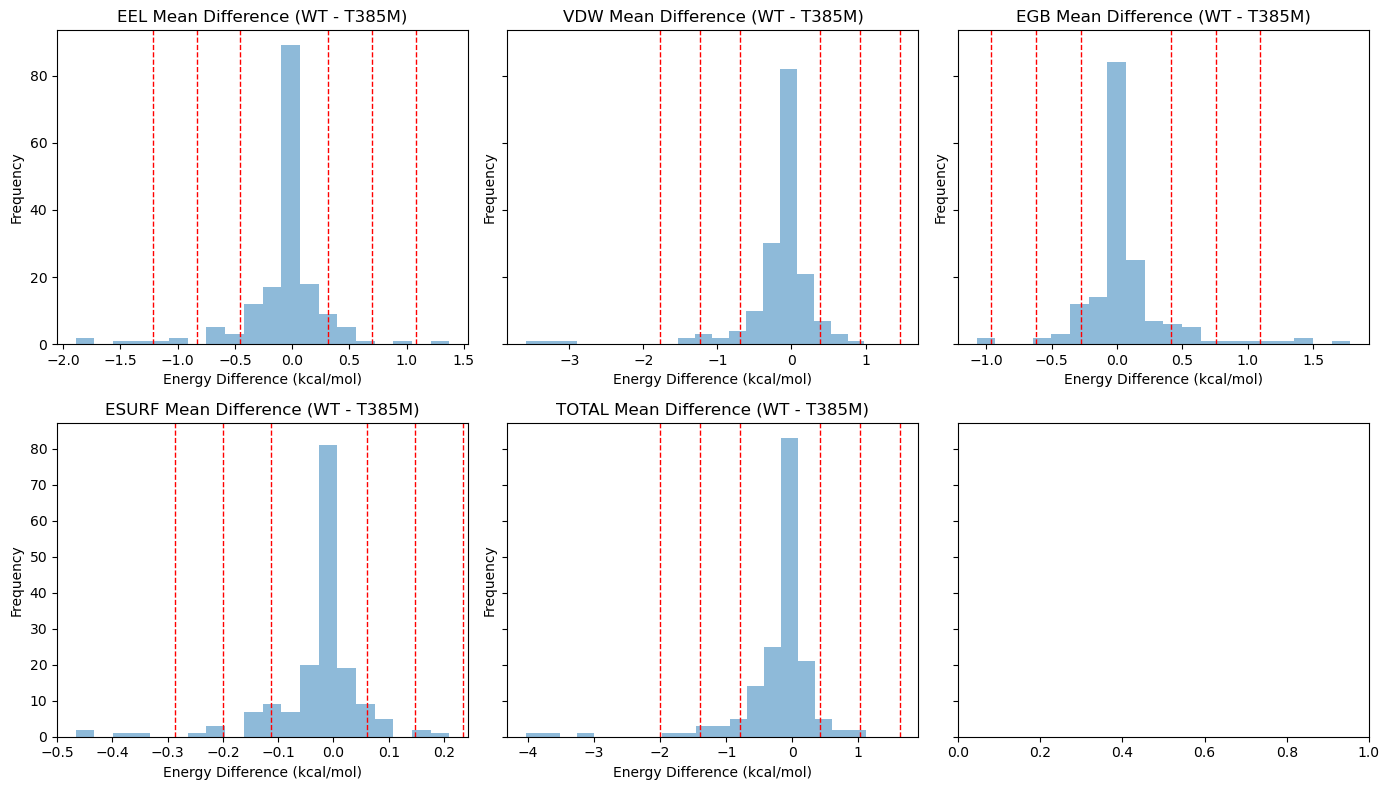

In [202]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey='row', squeeze=False)
axes_flat = axes.flatten()

# Dictionary to store values
sd_xvals = {}

for i, diff_col in enumerate(diff_columns):
    term_name = diff_col.replace('_diff', '')
    ax = axes_flat[i]

    data = common_df[diff_col].dropna()
    mean = data.mean()
    std = data.std()

    # Save values for this diff_col
    sd_xvals[diff_col] = {
        'mean': mean,
        'sd1': (mean - std, mean + std),
        'sd2': (mean - 2*std, mean + 2*std),
        'sd3': (mean - 3*std, mean + 3*std),
    }

    # Histogram
    ax.hist(data, bins=20, alpha=0.5)

    # Add vertical lines
    for n in [1, 2, 3]:
        ax.axvline(mean + n*std, color='red', linestyle='--', linewidth=1)
        ax.axvline(mean - n*std, color='red', linestyle='--', linewidth=1)

    ax.set_title(f'{term_name} Mean Difference (WT - T385M)')
    ax.set_xlabel('Energy Difference (kcal/mol)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()


EEL outlyers

In [204]:
# Show residues with Electrostatic difference greater than 2 standard deviations
common_df[
    (common_df['EEL_diff'] > sd_xvals['EEL_diff']['sd2'][1]) | (common_df['EEL_diff'] < sd_xvals['EEL_diff']['sd2'][0])
    ][['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_T385M', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_T385M,EEL_diff
58,279,B,2.937016,1.564741,1.372275
63,410,B,-1.483596,-2.500163,1.016567
32,411,B,0.841038,1.872874,-1.031836
28,157,B,-1.358812,-0.324321,-1.034491
35,181,B,-4.396414,-3.268656,-1.127758
64,161,B,-0.782974,0.510110,-1.293084
9,165,B,-6.300203,-4.750798,-1.549405
148,388,A,-7.085459,-5.239128,-1.846331
150,161,A,-0.795512,1.095077,-1.890589


VDW outliers

In [205]:
common_df[(common_df['VDW_diff'] > sd_xvals['VDW_diff']['sd2'][1]) | (common_df['VDW_diff'] < sd_xvals['VDW_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_T385M', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_T385M,VDW_diff
75,385,B,-1.599933,-2.585359,0.985426
40,406,B,-5.032528,-3.779188,-1.253340
8,179,B,-1.721560,-0.310985,-1.410576
66,175,B,-2.398483,-0.900862,-1.497621
128,406,A,-5.098180,-2.164188,-2.933992
138,383,A,-3.923769,-0.741900,-3.181870
72,172,B,-5.647312,-2.063772,-3.583540


EGB outliers

In [206]:
common_df[(common_df['EGB_diff'] > sd_xvals['EGB_diff']['sd2'][1]) | (common_df['EGB_diff'] < sd_xvals['EGB_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_T385M', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_T385M,EGB_diff
58,279,B,-2.389148,-1.315838,-1.073310
63,410,B,1.456753,2.427269,-0.970516
32,411,B,-0.805210,-1.704401,0.899192
28,157,B,1.540379,0.589993,0.950386
35,181,B,4.265303,3.175645,1.089657
64,161,B,0.793892,-0.432219,1.226111
9,165,B,5.891790,4.482788,1.409002
148,388,A,6.342661,4.919887,1.422774
150,161,A,0.879371,-0.903633,1.783004


ESURF outliers

In [207]:
common_df[(common_df['ESURF_diff'] > sd_xvals['ESURF_diff']['sd2'][1]) | (common_df['ESURF_diff'] < sd_xvals['ESURF_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_T385M', 'ESURF_diff']].sort_values('ESURF_diff', ascending=False)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_T385M,ESURF_diff
95,179,A,-0.073599,-0.283330,0.209731
64,161,B,-0.471011,-0.257289,-0.213723
66,175,B,-0.468746,-0.252329,-0.216417
40,406,B,-0.721737,-0.501900,-0.219837
150,161,A,-0.565589,-0.334258,-0.231331
128,406,A,-0.719867,-0.387219,-0.332648
8,179,B,-0.487265,-0.089418,-0.397848
72,172,B,-0.881011,-0.446291,-0.434721
138,383,A,-0.614558,-0.148027,-0.466530


TOTAL energy outliers

In [208]:
common_df[(common_df['TOTAL_diff'] > sd_xvals['TOTAL_diff']['sd2'][1]) | (common_df['TOTAL_diff'] < sd_xvals['TOTAL_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_T385M', 'TOTAL_diff']].sort_values('TOTAL_diff', ascending=False)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_T385M,TOTAL_diff
75,385,B,-0.281763,-0.325086,1.117824
66,175,B,-0.468746,-0.252329,-1.628057
8,179,B,-0.487265,-0.089418,-1.782591
128,406,A,-0.719867,-0.387219,-3.117871
138,383,A,-0.614558,-0.148027,-3.546188
72,172,B,-0.881011,-0.446291,-4.030699


### WT vs R274W_T385M

#### By replicate

/tmp/ipykernel_204777/773368267.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_chainA = R274W_T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
/tmp/ipykernel_204777/773368267.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_chainB = R274W_T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)


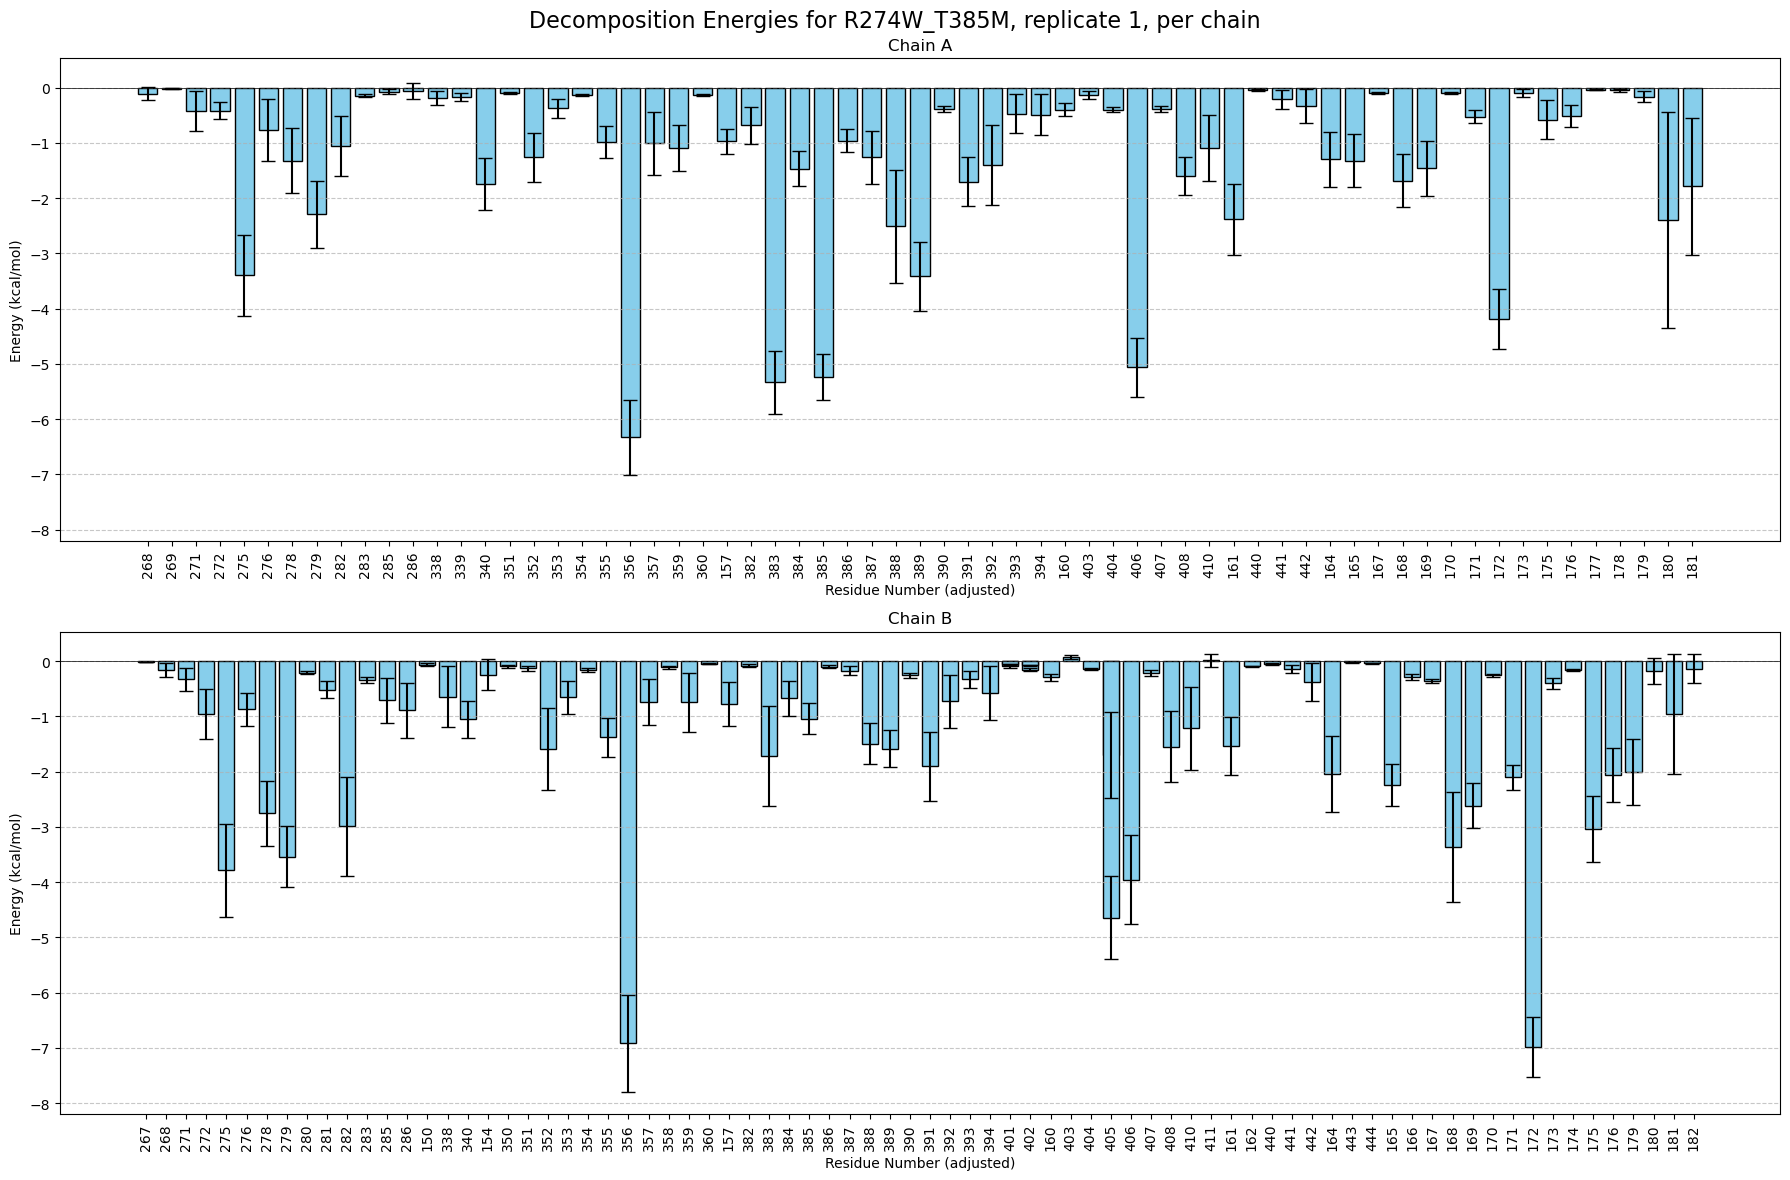

In [214]:
df_chainA = R274W_T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
df_chainB = R274W_T385M_decomp_summary[0][T385M_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)


fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharey=True)
ax1, ax2 = axes.flatten()
plots = [
    (df_chainA, ax1, 'Chain A'),
    (df_chainB, ax2, 'Chain B')
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for R274W_T385M, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

#### By mutation (combining replicates)

Zoom in on the mutated residue.

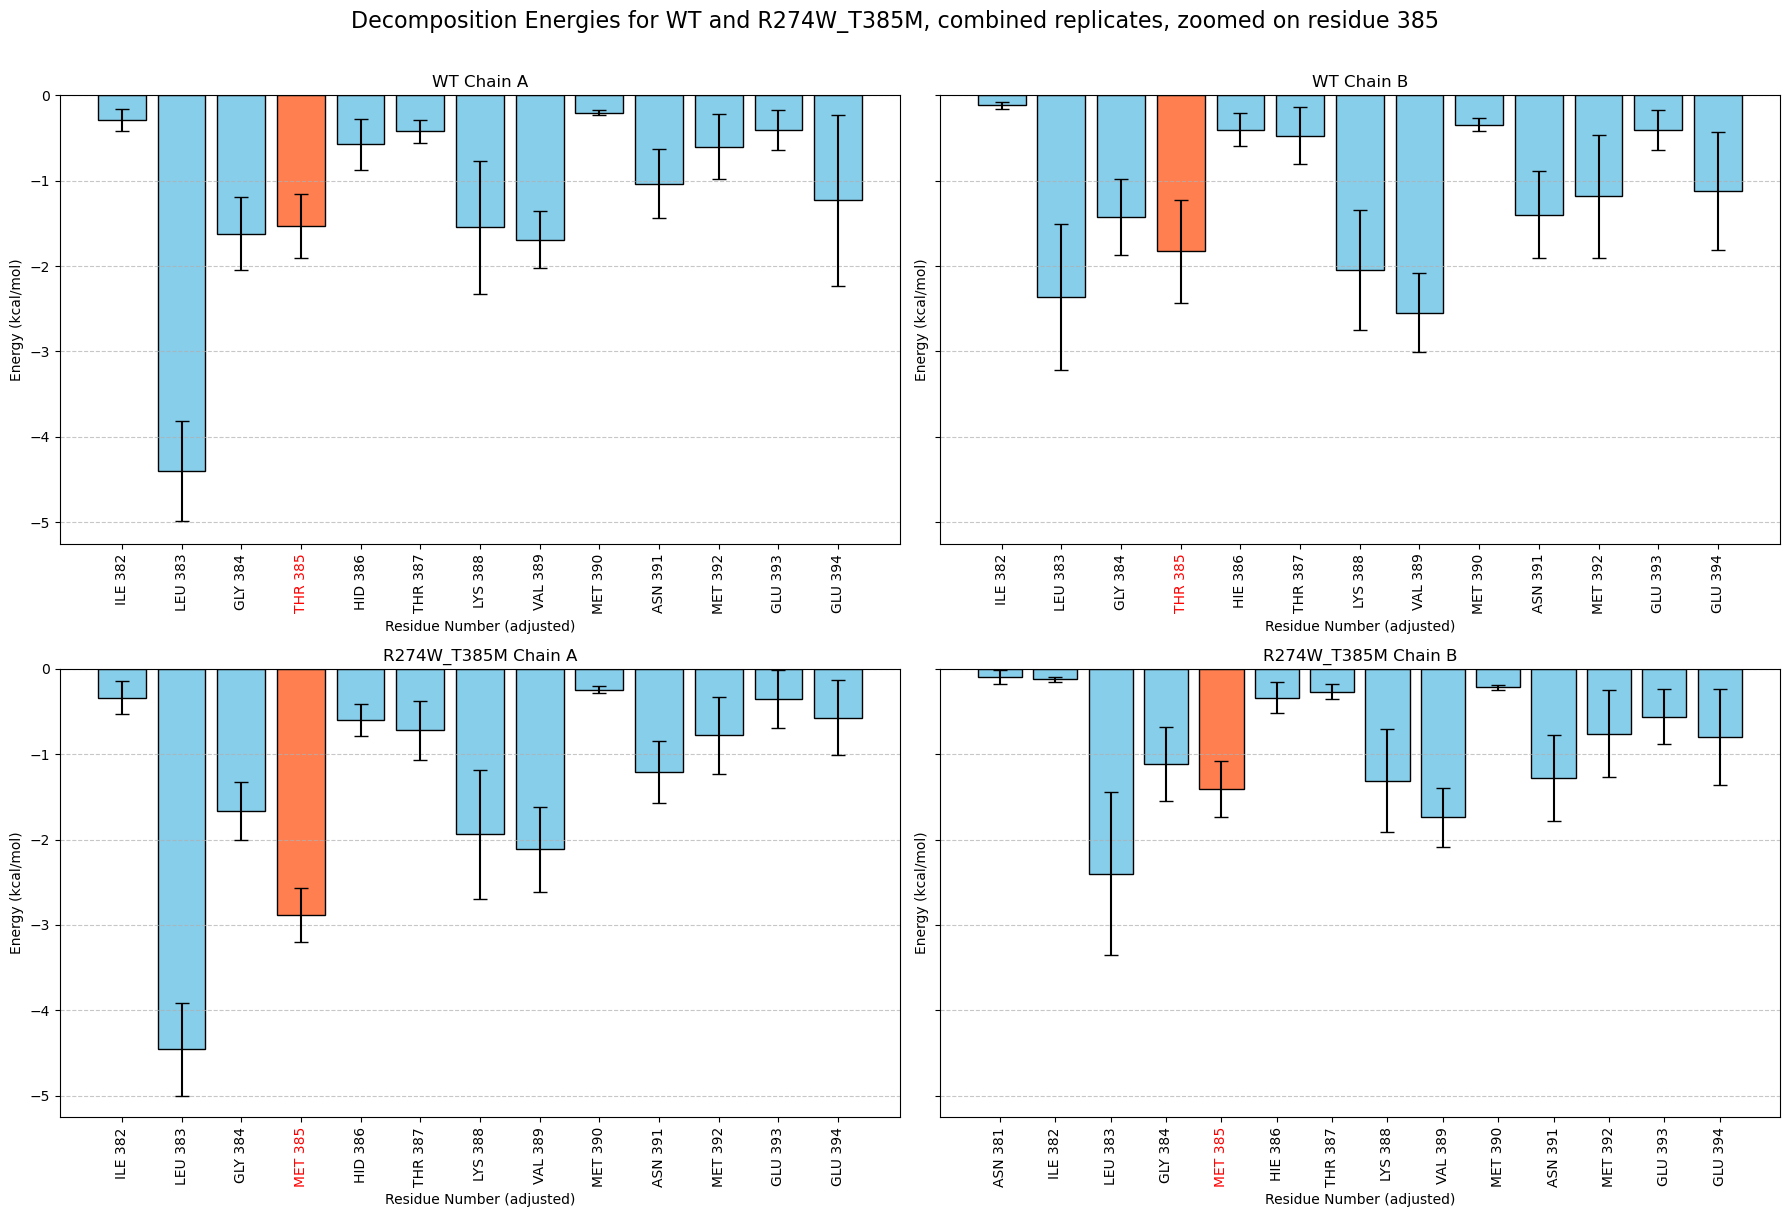

In [215]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_R274W_T385M_monoA = R274W_T385M_decomp_combined_df[R274W_T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_R274W_T385M_monoB = R274W_T385M_decomp_combined_df[R274W_T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_R274W_T385M_monoA, ax3, 'R274W_T385M Chain A'),
    (df_R274W_T385M_monoB, ax4, 'R274W_T385M Chain B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 375) & (df['resid_adj'].astype(int) < 395)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    # color the mutation site red
    colors = ['red' if int(resid) == 385 else 'black' for resid in filtered_df['resid_adj']]
    for ticklabel, color in zip(ax.get_xticklabels(), colors):
        ticklabel.set_color(color)
    # color de mutation bar red
    for bar, resid in zip(ax.patches, filtered_df['resid_adj']):
        if int(resid) == 385:
            bar.set_color('coral')
            bar.set_edgecolor('black')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and R274W_T385M, combined replicates, zoomed on residue 385', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

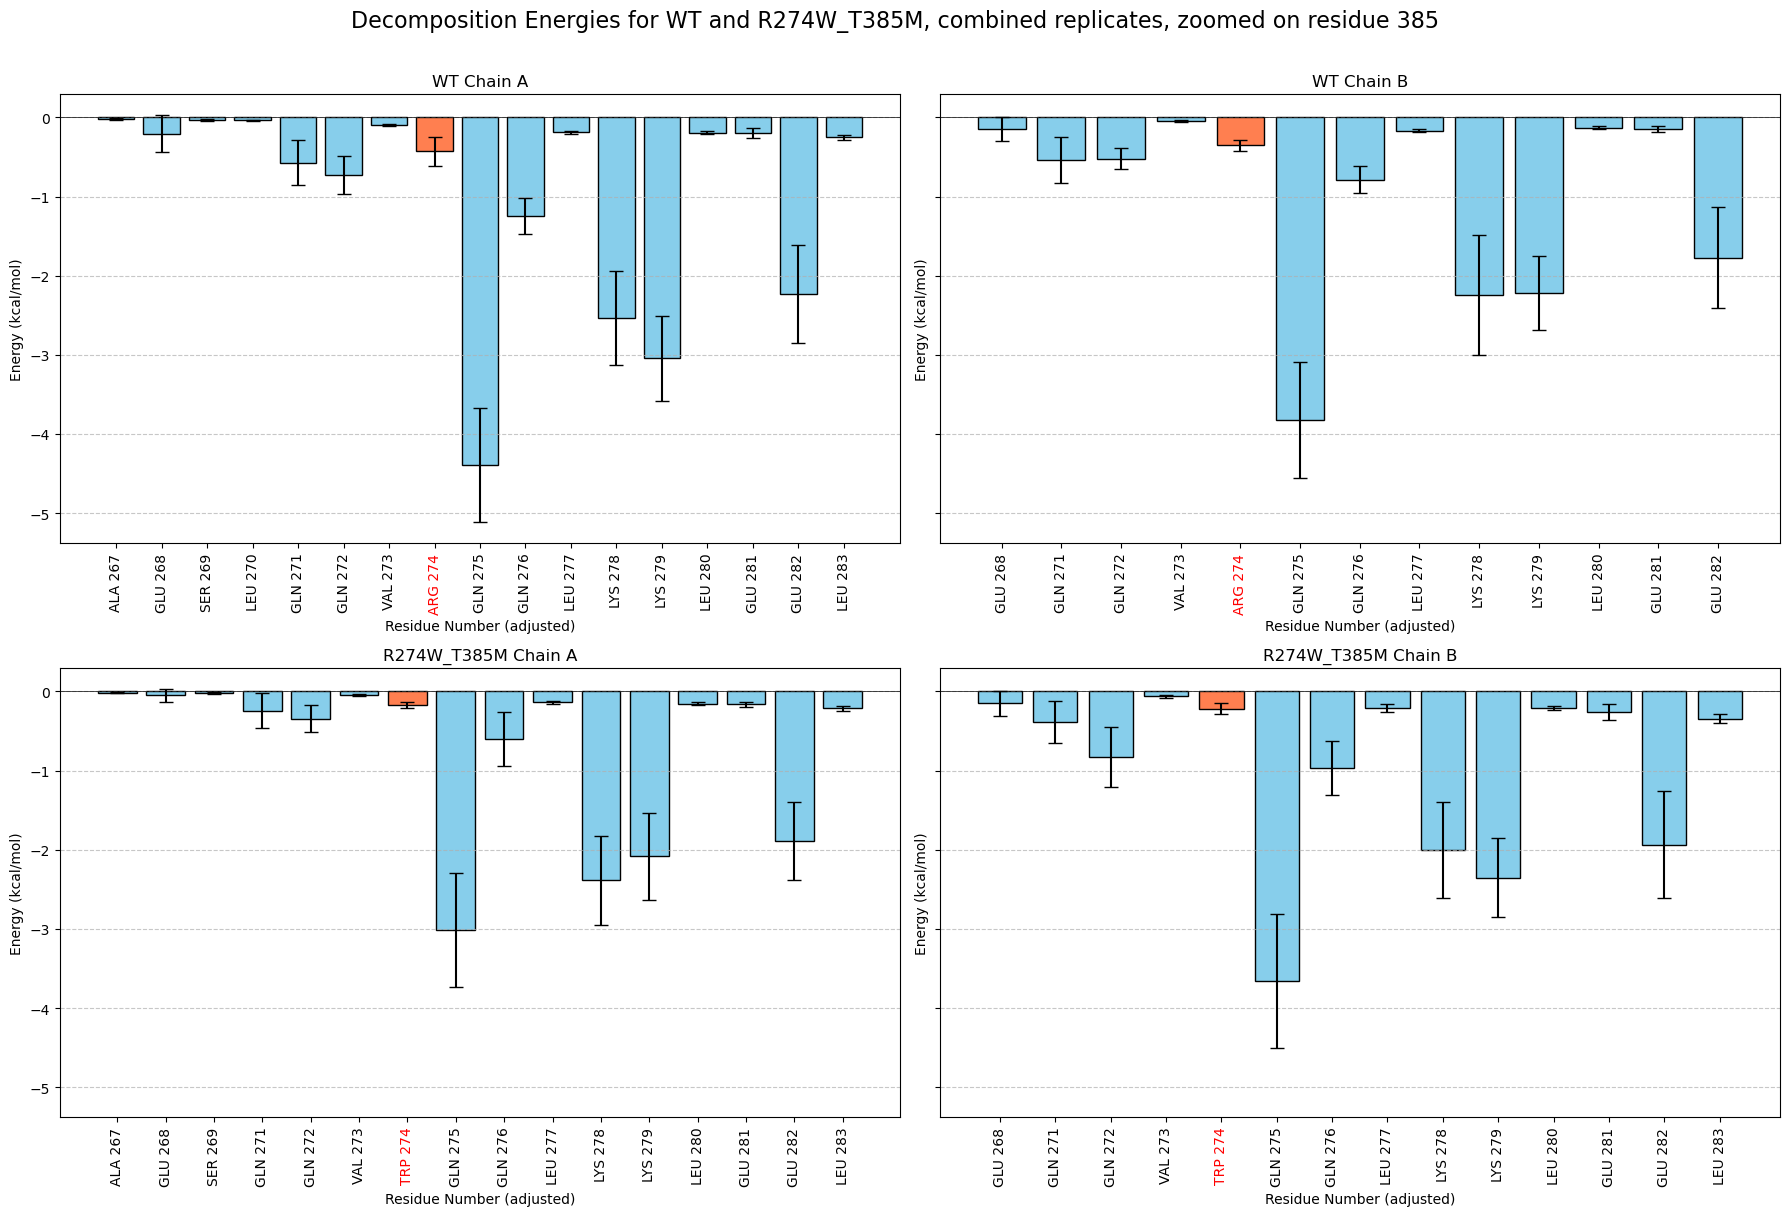

In [218]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_R274W_T385M_monoA, ax3, 'R274W_T385M Chain A'),
    (df_R274W_T385M_monoB, ax4, 'R274W_T385M Chain B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 264) & (df['resid_adj'].astype(int) < 284)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    # color the mutation site red
    colors = ['red' if int(resid) == 274 else 'black' for resid in filtered_df['resid_adj']]
    for ticklabel, color in zip(ax.get_xticklabels(), colors):
        ticklabel.set_color(color)
    # color de mutation bar red
    for bar, resid in zip(ax.patches, filtered_df['resid_adj']):
        if int(resid) == 274:
            bar.set_color('coral')
            bar.set_edgecolor('black')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and R274W_T385M, combined replicates, zoomed on residue 385', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

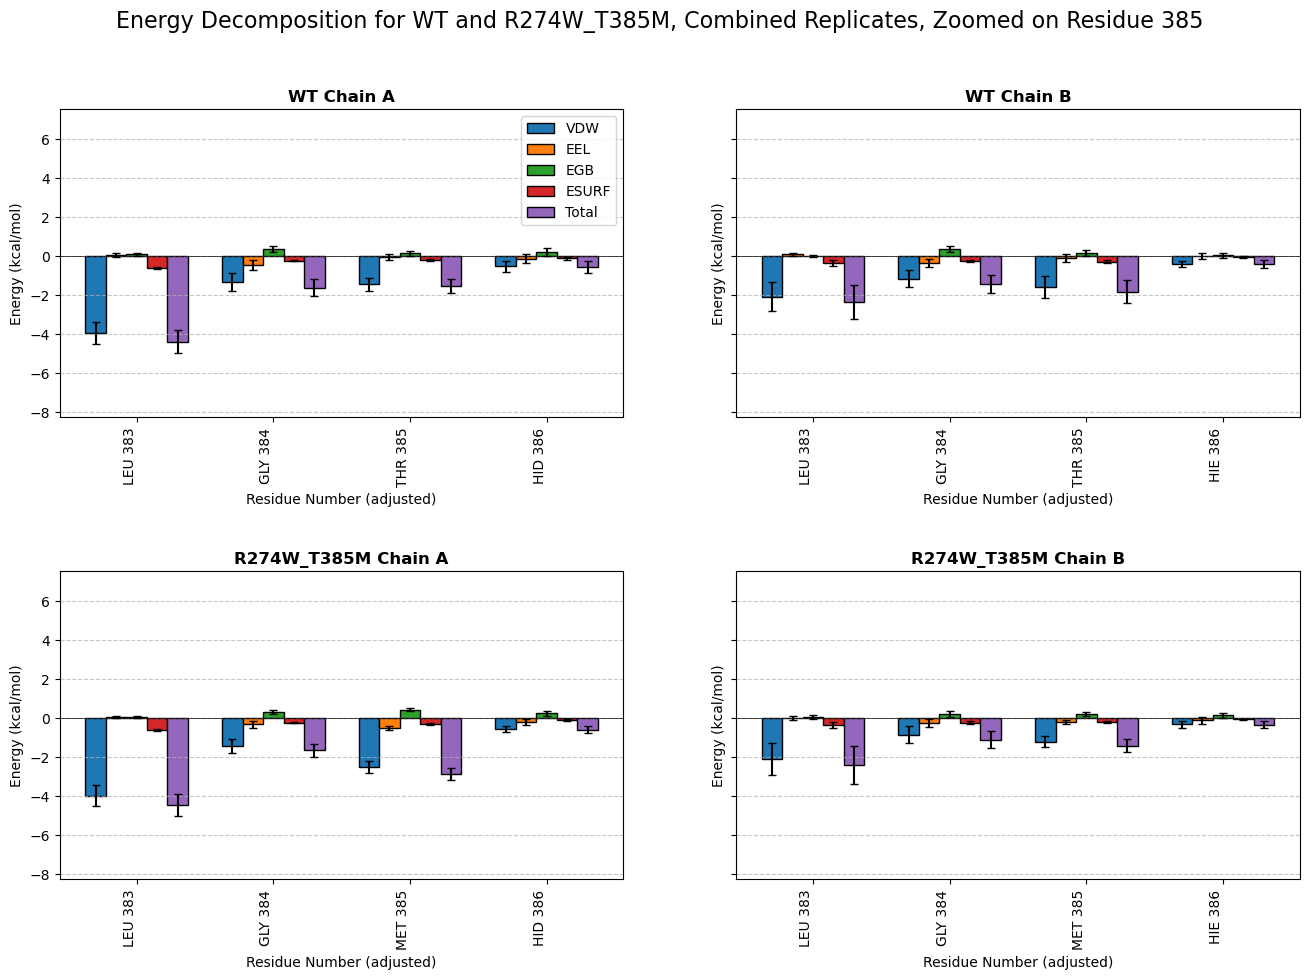

In [220]:
df_WT_monoA = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_R274W_T385M_monoA = R274W_T385M_decomp_combined_df[R274W_T385M_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_WT_monoB = WT_decomp_combined_df[WT_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_R274W_T385M_monoB = R274W_T385M_decomp_combined_df[R274W_T385M_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Define energy terms and their corresponding std columns
energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_R274W_T385M_monoA, ax3, 'R274W_T385M Chain A'),
    (df_R274W_T385M_monoB, ax4, 'R274W_T385M Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 380-390
    filtered_df = df[(df['resid_adj'].astype(int) > 382) & (df['resid_adj'].astype(int) < 387)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and R274W_T385M, Combined Replicates, Zoomed on Residue 385', fontsize=16)


plt.subplots_adjust(hspace=0.5)
plt.show()

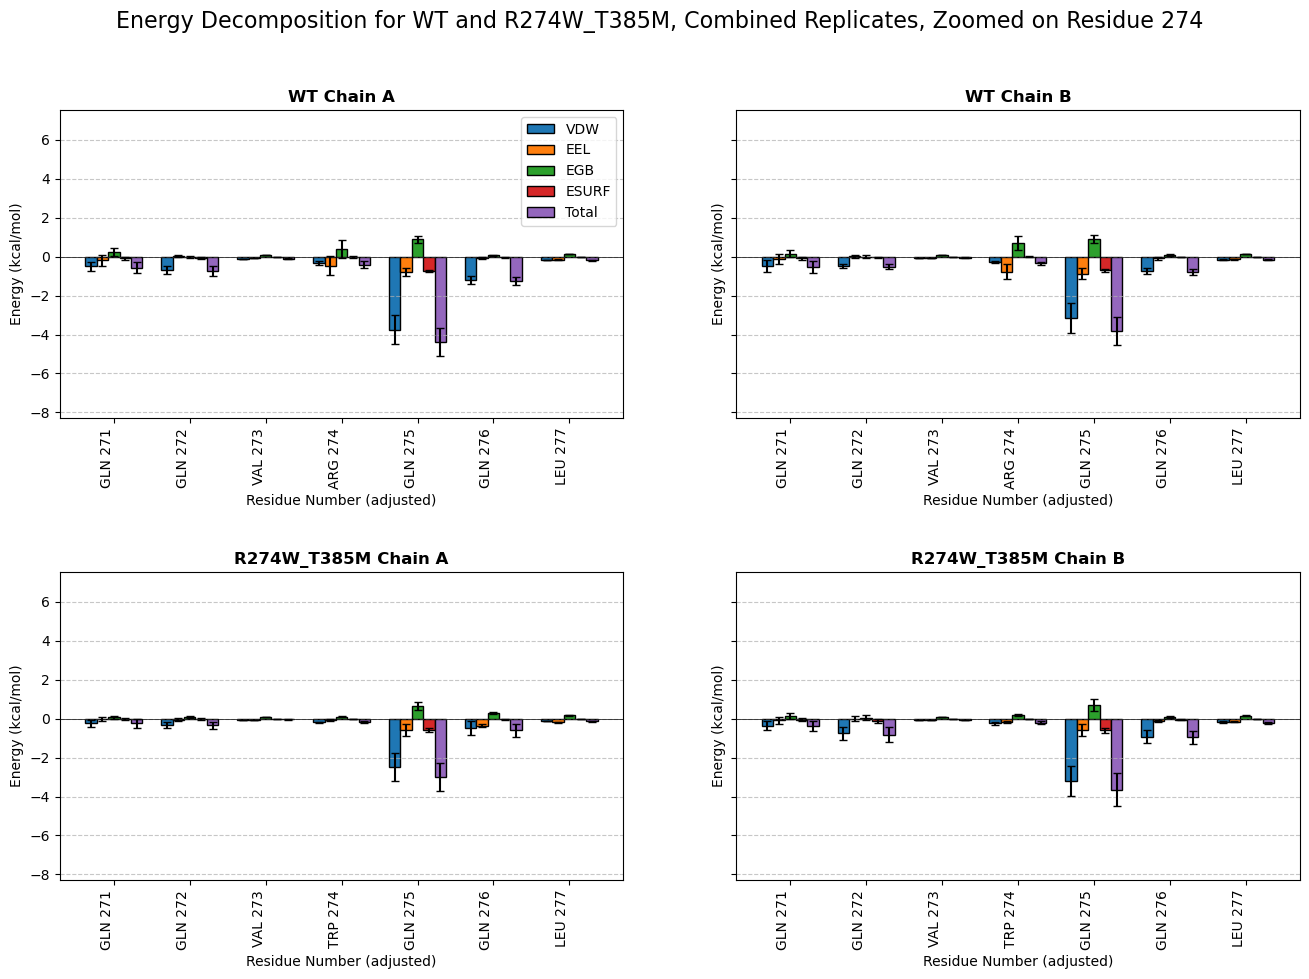

In [223]:
# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_WT_monoA, ax1, 'WT Chain A'),
    (df_WT_monoB, ax2, 'WT Chain B'),
    (df_R274W_T385M_monoA, ax3, 'R274W_T385M Chain A'),
    (df_R274W_T385M_monoB, ax4, 'R274W_T385M Chain B'),
]

for df, ax, title in plots:
    # Filter for residues in the range 380-390
    filtered_df = df[(df['resid_adj'].astype(int) > 270) & (df['resid_adj'].astype(int) < 278)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and R274W_T385M, Combined Replicates, Zoomed on Residue 274', fontsize=16)


plt.subplots_adjust(hspace=0.5)
plt.show()

In [224]:
# Merge WT and T419R DataFrames on 'resid_adj' and 'chain' to get common residues
common_df = WT_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean', 'TOTAL_mean']].merge(
    R274W_T385M_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean', 'TOTAL_mean']],
    on=['resid_adj', 'chain'],
    suffixes=('_WT', '_R274W_T385M')
)

# Calculate the differences (WT - T385M)
common_df['EEL_diff'] = common_df['Electrostatic_mean_WT'] - common_df['Electrostatic_mean_R274W_T385M']
common_df['VDW_diff'] = common_df['van der Waals_mean_WT'] - common_df['van der Waals_mean_R274W_T385M']
common_df['EGB_diff'] = common_df['Polar Solvation_mean_WT'] - common_df['Polar Solvation_mean_R274W_T385M']
common_df['ESURF_diff'] = common_df['Non-Polar Solv._mean_WT'] - common_df['Non-Polar Solv._mean_R274W_T385M']
common_df['TOTAL_diff'] = common_df['TOTAL_mean_WT'] - common_df['TOTAL_mean_R274W_T385M']

In [225]:
common_df.head()

,Residue_WT,resid_adj,chain,Electrostatic_mean_WT,Polar Solvation_mean_WT,van der Waals_mean_WT,Non-Polar Solv._mean_WT,TOTAL_mean_WT,Residue_R274W_T385M,Electrostatic_mean_R274W_T385M,Polar Solvation_mean_R274W_T385M,van der Waals_mean_R274W_T385M,Non-Polar Solv._mean_R274W_T385M,TOTAL_mean_R274W_T385M,EEL_diff,VDW_diff,EGB_diff,ESURF_diff,TOTAL_diff
0,L:B:ALA:268,401,B,0.018313,-0.003743,-0.071028,0.000000,-0.056337,L:B:ALA:268,0.000679,0.010619,-0.090928,-0.000629,-0.080165,0.017635,0.019900,-0.014361,0.000629,0.023827
1,L:B:ALA:269,402,B,-0.169586,0.164062,-0.088857,-0.000010,-0.094371,L:B:ALA:269,-0.192824,0.183743,-0.093503,-0.000240,-0.102824,0.023239,0.004646,-0.019681,0.000230,0.008453
2,L:B:ARG:141,274,B,-0.766277,0.685170,-0.268234,-0.003024,-0.352455,L:B:TRP:141,-0.158333,0.176168,-0.231447,-0.001542,-0.215225,-0.607944,-0.036786,0.509002,-0.001482,-0.137231
3,L:B:ARG:272,405,B,-5.088666,4.650429,-1.521051,-0.345459,-2.304764,L:B:ARG:272,-7.621710,6.831008,-1.826248,-0.485971,-3.102924,2.533044,0.305196,-2.180579,0.140512,0.798160
4,L:B:ARG:47,180,B,3.589381,-3.447638,-0.402731,-0.034963,-0.295898,L:B:ARG:47,3.512641,-3.361031,-0.249963,-0.016035,-0.114451,0.076740,-0.152768,-0.086607,-0.018929,-0.181447


Residues not in both dfs

In [226]:
# Perform an outer merge to include all residues and their associated columns
merged_df = WT_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    R274W_T385M_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    how='outer',
    indicator=True,
    suffixes=('_WT', '_R274W_T385M')
)

# Filter for residues that are only in one DataFrame
non_common_df = merged_df[merged_df['_merge'] != 'both'].copy()

# Create a column to indicate which DataFrame the residue is from
non_common_df['Source'] = non_common_df['_merge'].map({
    'left_only': 'WT',
    'right_only': 'R274W_T385M'
})

# Create consolidated columns for the energy terms, prioritizing WT or T385M values
non_common_df['Electrostatic_mean'] = non_common_df['Electrostatic_mean_WT'].fillna(non_common_df['Electrostatic_mean_R274W_T385M'])
non_common_df['Polar Solvation_mean'] = non_common_df['Polar Solvation_mean_WT'].fillna(non_common_df['Polar Solvation_mean_R274W_T385M'])
non_common_df['van der Waals_mean'] = non_common_df['van der Waals_mean_WT'].fillna(non_common_df['van der Waals_mean_R274W_T385M'])
non_common_df['Non-Polar Solv._mean'] = non_common_df['Non-Polar Solv._mean_WT'].fillna(non_common_df['Non-Polar Solv._mean_R274W_T385M'])

# Select relevant columns for the final table
result_df = non_common_df[['resid_adj', 'chain', 'Source', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']]

# Print the table
result_df

,resid_adj,chain,Source,Electrostatic_mean,Polar Solvation_mean,van der Waals_mean,Non-Polar Solv._mean
12,155,B,WT,-0.078453,0.078633,-0.018952,0.000000
87,445,B,WT,-0.014461,0.015908,-0.019571,0.000000
91,415,A,WT,-0.027221,0.025624,-0.012655,-0.000644
94,418,A,WT,-0.691467,0.666577,-0.010449,-0.000210
130,416,A,WT,-0.021826,0.023004,-0.066687,-0.006218
135,156,A,WT,-0.093583,0.091218,-0.093313,0.000000
138,270,A,WT,-0.030798,0.042186,-0.047635,0.000000
147,409,A,WT,0.036996,-0.033283,-0.095918,0.000000
172,417,A,WT,0.030908,-0.025788,-0.024152,-0.000469
180,381,B,R274W_T385M,0.024461,-0.006856,-0.103054,-0.006627


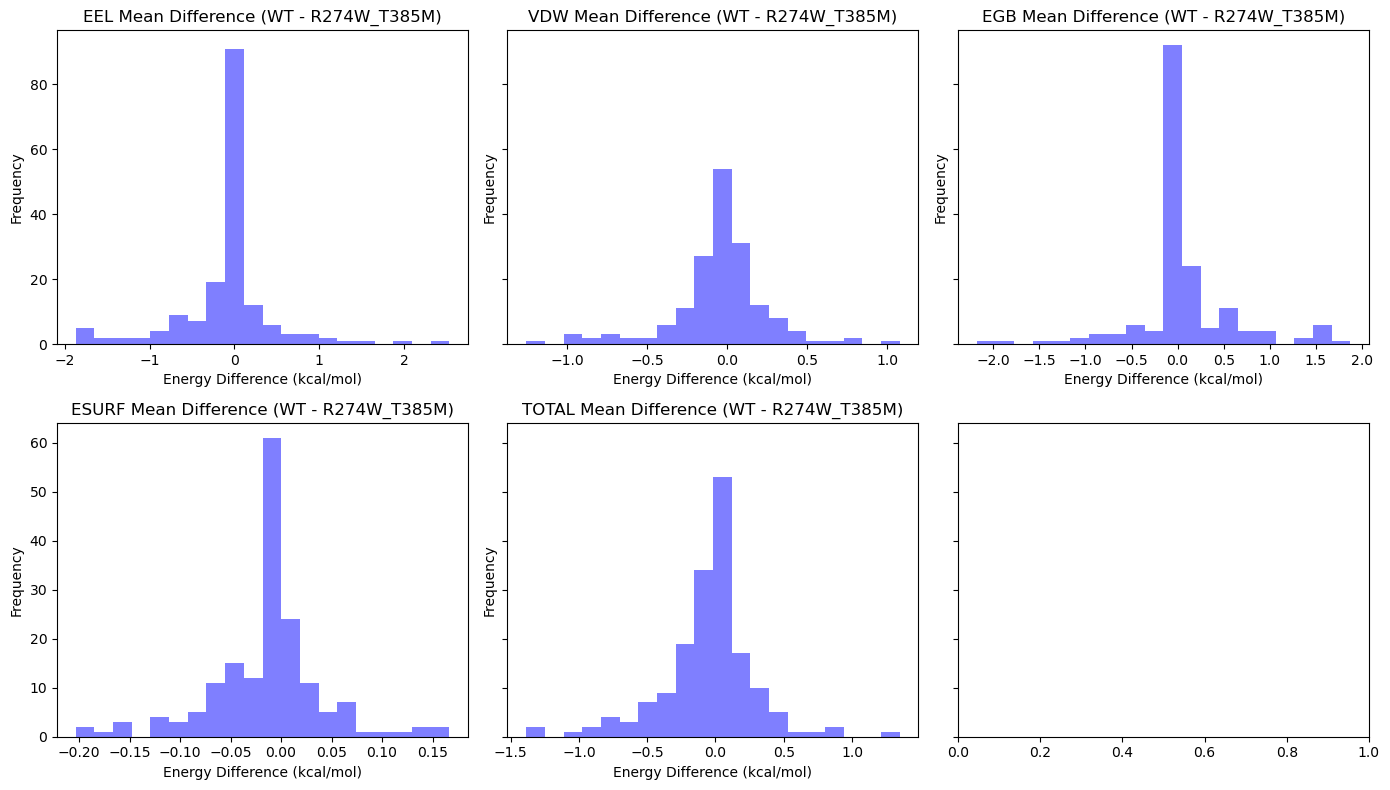

In [228]:
# columns ending in '_diff'
diff_columns = common_df.filter(like='_diff').columns

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey='row', squeeze=False)
axes_flat = axes.flatten()

for i, diff_col in enumerate(diff_columns):
    # Extract the energy term name
    term_name = diff_col.replace('_diff', '')
    ax = axes_flat[i]
    # All residues
    ax.hist(common_df[diff_col], bins=20, alpha=0.5, color='blue')
    ax.set_title(f'{term_name} Mean Difference (WT - R274W_T385M)')
    ax.set_xlabel('Energy Difference (kcal/mol)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

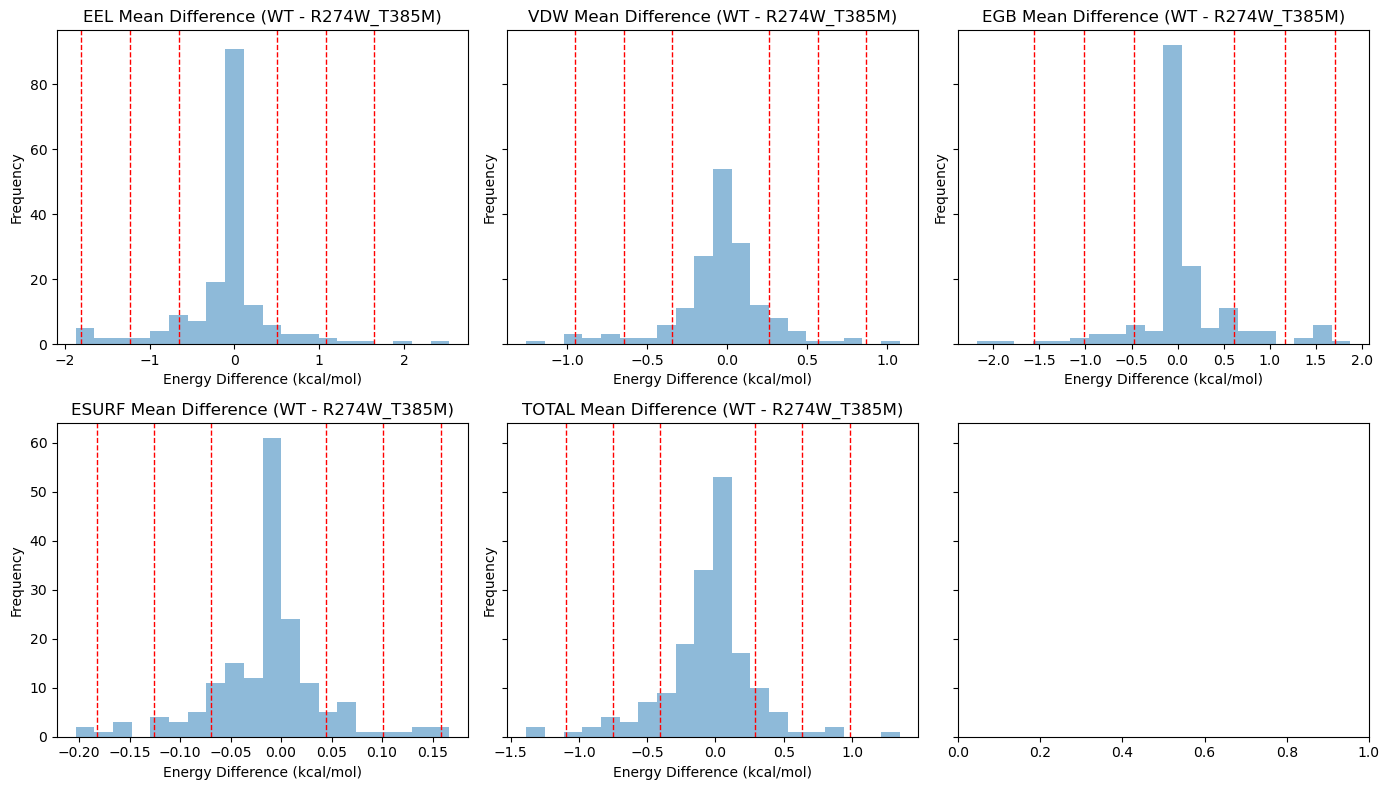

In [229]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey='row', squeeze=False)
axes_flat = axes.flatten()

# Dictionary to store values
sd_xvals = {}

for i, diff_col in enumerate(diff_columns):
    term_name = diff_col.replace('_diff', '')
    ax = axes_flat[i]

    data = common_df[diff_col].dropna()
    mean = data.mean()
    std = data.std()

    # Save values for this diff_col
    sd_xvals[diff_col] = {
        'mean': mean,
        'sd1': (mean - std, mean + std),
        'sd2': (mean - 2*std, mean + 2*std),
        'sd3': (mean - 3*std, mean + 3*std),
    }

    # Histogram
    ax.hist(data, bins=20, alpha=0.5)

    # Add vertical lines
    for n in [1, 2, 3]:
        ax.axvline(mean + n*std, color='red', linestyle='--', linewidth=1)
        ax.axvline(mean - n*std, color='red', linestyle='--', linewidth=1)

    ax.set_title(f'{term_name} Mean Difference (WT - R274W_T385M)')
    ax.set_xlabel('Energy Difference (kcal/mol)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()


EEL outlyers

In [233]:
# Show residues with Electrostatic difference greater than 2 standard deviations
common_df[
    (common_df['EEL_diff'] > sd_xvals['EEL_diff']['sd2'][1]) | (common_df['EEL_diff'] < sd_xvals['EEL_diff']['sd2'][0])
    ][['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_R274W_T385M', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_R274W_T385M,EEL_diff
3,405,B,-5.088666,-7.621710,2.533044
63,410,B,-1.483596,-3.568723,2.085126
123,181,A,-3.922961,-5.416956,1.493995
152,175,A,4.846949,3.567618,1.279331
29,393,B,0.642751,2.012678,-1.369927
118,394,A,-0.373423,1.007927,-1.381351
116,157,A,-1.651979,-0.117542,-1.534438
30,394,B,-0.100439,1.480333,-1.580772
114,282,A,-5.729178,-4.069704,-1.659474
32,411,B,0.841038,2.509584,-1.668546


VDW outliers

In [234]:
common_df[(common_df['VDW_diff'] > sd_xvals['VDW_diff']['sd2'][1]) | (common_df['VDW_diff'] < sd_xvals['VDW_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_R274W_T385M', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_R274W_T385M,VDW_diff
162,385,A,-1.442445,-2.519797,1.077352
9,165,B,-0.585100,-1.342029,0.756929
90,405,A,-0.918283,-1.650293,0.732009
91,180,A,-0.124777,-0.849498,0.724721
123,181,A,-0.197142,-0.767668,0.570526
62,388,B,-1.052182,-0.379707,-0.672475
104,276,A,-1.190050,-0.487931,-0.702119
5,355,B,-1.774907,-1.070579,-0.704328
27,353,B,-1.291710,-0.490762,-0.800948
144,279,A,-3.152618,-2.266890,-0.885729


EGB outliers

In [235]:
common_df[(common_df['EGB_diff'] > sd_xvals['EGB_diff']['sd2'][1]) | (common_df['EGB_diff'] < sd_xvals['EGB_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_R274W_T385M', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_R274W_T385M,EGB_diff
3,405,B,4.650429,6.831008,-2.180579
63,410,B,1.456753,3.392299,-1.935546
123,181,A,3.797848,5.212249,-1.414401
152,175,A,-4.403593,-3.220662,-1.182931
143,278,A,0.320413,1.452728,-1.132315
118,394,A,0.352971,-0.923683,1.276653
29,393,B,-0.564255,-1.893350,1.329095
9,165,B,5.891790,4.420629,1.471161
30,394,B,0.103979,-1.374711,1.478689
32,411,B,-0.805210,-2.353583,1.548373


ESURF outliers

In [236]:
common_df[(common_df['ESURF_diff'] > sd_xvals['ESURF_diff']['sd2'][1]) | (common_df['ESURF_diff'] < sd_xvals['ESURF_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_R274W_T385M', 'ESURF_diff']].sort_values('ESURF_diff', ascending=False)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_R274W_T385M,ESURF_diff
123,181,A,-0.061527,-0.228144,0.166617
91,180,A,-0.011377,-0.175446,0.164069
3,405,B,-0.345459,-0.485971,0.140512
63,410,B,-0.083962,-0.223267,0.139305
162,385,A,-0.180605,-0.295719,0.115113
96,179,A,-0.073599,-0.179671,0.106071
120,411,A,-0.139900,-0.010739,-0.129162
27,353,B,-0.245778,-0.082545,-0.163234
79,356,B,-1.131035,-0.966424,-0.164611
118,394,A,-0.306976,-0.141474,-0.165502


TOTAL energy outliers

In [237]:
common_df[(common_df['TOTAL_diff'] > sd_xvals['TOTAL_diff']['sd2'][1]) | (common_df['TOTAL_diff'] < sd_xvals['TOTAL_diff']['sd2'][0])][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_R274W_T385M', 'TOTAL_diff']].sort_values('TOTAL_diff', ascending=False)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_R274W_T385M,TOTAL_diff
162,385,A,-0.180605,-0.295719,1.349661
91,180,A,-0.011377,-0.175446,0.881314
123,181,A,-0.061527,-0.228144,0.816900
3,405,B,-0.345459,-0.485971,0.798160
98,168,A,-0.465619,-0.420070,-0.795699
85,389,B,-0.360955,-0.269787,-0.809624
144,279,A,-0.453450,-0.411916,-0.963550
27,353,B,-0.245778,-0.082545,-0.964009
6,357,B,-0.329145,-0.125729,-1.110120
79,356,B,-1.131035,-0.966424,-1.251384
